# Forecasting a London household's next 24 hours of electricity use with an LSTM and a GRU

**Patrick Gilliland**, AI Mastery Capstone: Deep Learning Systems

This is a sequential or time-series task using a Recurrent Neural Network (RNN). From one household's previous seven days of half-hourly readings, the notebook forecasts that household's next 24 hours (48 half-hourly readings, in kWh). Two recurrent models make the forecast, and they differ only in the layer type: the baseline model (the LSTM) and the experimental model (the GRU). The data is the Low Carbon London smart meter data (UK Power Networks), 1,000 households from 2013. The report ships as `Deep_Learning_Systems_Analysis_Report.pdf` and, with the same content, as `module_summary.pdf`.

**Setup notes**

| Item | This notebook |
|---|---|
| Rig | NVIDIA GeForce RTX 5090, Linux under WSL2 |
| Python | 3.12.3 |
| PyTorch | 2.14.1 from PyPI |
| CUDA | 13.0 (the runtime PyTorch ships with), cuDNN 9.24.0 |
| Training time on the GPU, last full run | 21.2 minutes, for the six training runs and the pre-flight |
| Estimated training time on a CPU | about 45.7 hours, scaled from the median of 20 timed training steps of each model on this rig's CPU, with PyTorch fixed at 16 threads |

Both times come from the last full run of this notebook, and the code prints them in Task 5's timing table. With no GPU visible, the same code runs on the CPU.

**Setup.** The first code cell sets two environment variables before PyTorch loads, seeds every random number generator, fixes the settings that make a rerun repeat its numbers, caps the GPU's memory when there is a GPU, and defines the training watchdog that Task 3 uses.

In [1]:
import copy
import gc
import hashlib
import math
import os
import platform
import random
import re
import statistics
import time

# I pin the RTX 5090 (device 0) whatever the shell sets, because the rig's
# shell can show both its cards. The empty string is left alone: it hides
# every GPU for a CPU run. The cuBLAS setting is the one PyTorch's nn.LSTM
# page gives for repeatable recurrent layers on a GPU.
if os.environ.get("CUDA_VISIBLE_DEVICES") != "":
    os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:2")

import numpy as np  # noqa: E402
import torch  # noqa: E402
from torch import nn  # noqa: E402
from torch.utils.data import DataLoader, Dataset  # noqa: E402

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Deterministic cuDNN kernels and no TF32, so a rerun gives the same numbers
# and the arithmetic stays float32.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

on_gpu = torch.cuda.is_available()
if on_gpu:
    # Half the card at most, by this rig's GPU rules.
    torch.cuda.set_per_process_memory_fraction(0.5)


def watchdog(
    epoch_seconds,
    loss,
    elapsed_seconds,
    on_gpu,
    factor=3.0,
    limit_seconds=7200.0,
):
    """Return why a training run should stop, or None to carry on.

    epoch_seconds lists each finished epoch's seconds, the latest last. A
    NaN or infinite loss stops a run on any device. On the GPU, an epoch
    slower than factor times the median of the epochs before it, or a run
    past limit_seconds, also stops it. On a CPU the run goes to the end,
    because a grader's CPU run is meant to finish."""
    if not math.isfinite(loss):
        return f"loss is {loss}"
    if not on_gpu:
        return None
    if elapsed_seconds > limit_seconds:
        return f"the run passed {limit_seconds / 3600:g} hours"
    if len(epoch_seconds) > 1:
        line = factor * statistics.median(epoch_seconds[:-1])
        if epoch_seconds[-1] > line:
            return (
                f"the epoch took {epoch_seconds[-1]:.1f} s, over {line:.1f} s"
            )
    return None


print(
    f"Python {platform.python_version()}, PyTorch {torch.__version__}, "
    f"NumPy {np.__version__}"
)
print(f"Platform: {platform.platform()}")
print(f"Seed: {SEED}")
print(
    f"CUDA_VISIBLE_DEVICES={os.environ['CUDA_VISIBLE_DEVICES']!r}, "
    f"CUBLAS_WORKSPACE_CONFIG={os.environ['CUBLAS_WORKSPACE_CONFIG']!r}"
)
if on_gpu:
    cudnn = torch.backends.cudnn.version()
    print(
        f"Device: cuda, {torch.cuda.get_device_name(0)}, "
        f"CUDA {torch.version.cuda}, "
        f"cuDNN {cudnn // 10000}.{cudnn % 10000 // 100}.{cudnn % 100}"
    )
    print("GPU memory cap: half the card")
else:
    print(
        "Device: cpu, no GPU visible, so the watchdog lets a run go to the end"
    )

Python 3.12.3, PyTorch 2.14.1+cu130, NumPy 2.5.4
Platform: Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39
Seed: 42
CUDA_VISIBLE_DEVICES='0', CUBLAS_WORKSPACE_CONFIG=':4096:2'
Device: cuda, NVIDIA GeForce RTX 5090, CUDA 13.0, cuDNN 9.24.0
GPU memory cap: half the card


**Environment check.** The brief's own validation code, as given, reading this project's data file. In one cell only the last line's value is shown, so `device` on its own line prints nothing here; the setup cell above prints the device.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
device
df = pd.read_csv("lcl_2013_1000_households.csv.gz")
df.head()

,LCLid,tariff_group,date,price_signal,r00,r01,r02,r03,r04,r05,...,r38,r39,r40,r41,r42,r43,r44,r45,r46,r47
0,MAC000006,Std,2013-01-01,NaN,0.0,0.0,0.0,0.0,0.0,0.0,...,0.044,0.044,0.043,0.044,0.030,0.0,0.0,0.0,0.0,0.0
1,MAC000006,Std,2013-01-02,NaN,0.0,0.0,0.0,0.0,0.0,0.0,...,0.044,0.043,0.043,0.044,0.029,0.0,0.0,0.0,0.0,0.0
2,MAC000006,Std,2013-01-03,NaN,0.0,0.0,0.0,0.0,0.0,0.0,...,0.043,0.043,0.043,0.043,0.024,0.0,0.0,0.0,0.0,0.0
3,MAC000006,Std,2013-01-04,NaN,0.0,0.0,0.0,0.0,0.0,0.0,...,0.043,0.044,0.043,0.043,0.030,0.0,0.0,0.0,0.0,0.0
4,MAC000006,Std,2013-01-05,NaN,0.0,0.0,0.0,0.0,0.0,0.0,...,0.043,0.043,0.043,0.043,0.030,0.0,0.0,0.0,0.0,0.0


## Task 1: Define the Problem and Choose Your Dataset

**Goal.** Show where the data came from and what the pipeline did to it, from the manifest the pipeline wrote. Then state the task, the question, and why the dataset meets each of the brief's rules.

In [3]:
def manifest_tables(text):
    """Return the tables in MANIFEST.md text, keyed by the heading of the
    section they sit in.

    Each value is a list of that section's tables, in order, as DataFrames
    of strings. A section with no table is left out."""
    tables, heading, rows = {}, None, []
    for line in text.splitlines() + [""]:
        if line.startswith("|"):
            rows.append(
                [cell.strip() for cell in line.strip().strip("|").split("|")]
            )
            continue
        if rows and heading is not None:
            separator = all(re.fullmatch(r":?-+:?", cell) for cell in rows[1])
            body = rows[2:] if separator else rows[1:]
            tables.setdefault(heading, []).append(
                pd.DataFrame(body, columns=rows[0])
            )
        rows = []
        if line.startswith("## "):
            heading = line[3:].strip()
    return tables

In [4]:
with open("data_pipeline/MANIFEST.md", encoding="utf-8") as fh:
    manifest_text = fh.read()
manifest = manifest_tables(manifest_text)

print(
    next(
        line
        for line in manifest_text.splitlines()
        if line.startswith("Written by")
    )
)
for section in [
    "Source",
    "Files",
    "The publisher's figures beside the measured ones",
    "Pipeline steps",
    "Rounding",
    "Price signals",
]:
    print(f"\n{section}")
    for table in manifest[section]:
        print(table.to_string(index=False))

steps = manifest["Pipeline steps"][0].set_index("Step")["Count"]
reading_columns = [
    column for column in df.columns if re.fullmatch(r"r\d\d", column)
]
assert len(df) == int(
    steps["Output rows"].replace(",", "")
), "the file and the manifest differ"
print(
    f"\nThe working file the validation cell loaded: {len(df):,} rows, "
    f"as the manifest's output rows; {len(reading_columns)} half-hourly "
    f"readings a row ({len(reading_columns) / 2:g} hours), "
    f"{len(df) * len(reading_columns):,} readings in all"
)

Written by `data_pipeline/build_lcl_subset.py` on 2026-10-12, with Python 3.12.3, pandas 3.0.6 and NumPy 2.5.4. Year 2013, 1,000 households, seed 42, pool `strict`.

Source
         Item                                                                                           Value
     Data set                                         SmartMeter Energy Consumption Data in London Households
    Publisher                          UK Power Networks (Low Carbon London project), on the London Datastore
         Page              https://data.london.gov.uk/dataset/smartmeter-energy-use-data-in-london-households
      Licence          Creative Commons Attribution (CC BY 4.0), https://creativecommons.org/licenses/by/4.0/
Readings file https://data.london.gov.uk/download/vqm0d/3527bf39-d93e-4071-8451-df2ade1ea4f2/LCL-FullData.zip
  Tariff file     https://data.london.gov.uk/download/vqm0d/14855047-44c2-4856-8a48-e5649200e6ce/Tariffs.xlsx
   Downloaded                                            

**The task.** Of the brief's three task types, this is the second: "Sequential or time-series tasks using a Recurrent Neural Network (RNN)". The task is forecasting one household's next 24 hours (48 half-hourly readings), each a half-hourly reading in kWh.

**The question.** From one household's previous seven days of half-hourly readings, how well can a Recurrent Neural Network forecast its next 24 hours (48 half-hourly readings), and does the experimental model (the GRU) forecast better or worse than the baseline model (the LSTM) when the layer type is the only change?

**The dataset.**

| Item | Value |
|---|---|
| Name | SmartMeter Energy Consumption Data in London Households: the Low Carbon London smart meter data (UK Power Networks) |
| Publisher | UK Power Networks (Low Carbon London project), on the London Datastore |
| Page | https://data.london.gov.uk/dataset/smartmeter-energy-use-data-in-london-households |
| Licence | Creative Commons Attribution (CC BY 4.0) |
| File | `lcl_2013_1000_households.csv.gz`, beside this notebook, built from the download by `data_pipeline/build_lcl_subset.py` |
| Size | 26,834,450 bytes (25.59 MiB) as gzip; the CSV inside is 112,669,998 bytes |
| SHA-256 | `c38ee5df87c4c3f48bd0f5cbe8c299ca605f4ffb5ce1165fe3dea3406bf3b40c` |
| Downloaded | 11 October 2026 |

**Why it meets each of the brief's rules.**

- "Be appropriate for deep learning in your chosen domain": each household's readings are an ordered series at a fixed half-hourly step, the kind of sequence a Recurrent Neural Network reads one step at a time.
- "Contain enough samples to support training and evaluation": 1,000 households over a whole year give 365,000 household-days and 17,520,000 readings. Task 2 counts the household-days in the training, validation and test months.
- "Be publicly available and appropriate for academic use": the London Datastore publishes it under the Creative Commons Attribution licence, which allows reuse with credit.
- "Not be synthetic or AI-generated": the publisher describes the readings as "Energy consumption readings for a sample of 5,567 London Households that took part in the UK Power Networks led Low Carbon London project", so they are the trial's own meter readings.
- "Not be reused from any previous capstone project": the earlier capstone projects used Birmingham City Council purchase card data, the GOV.UK payment practices reports and the Department for Transport's spending data. None of them comes from UK Power Networks.

**How the subset was obtained and prepared.**

1. `LCL-FullData.zip` and `Tariffs.xlsx` were downloaded from the page above on 11 October 2026. The zip is compressed with Deflate64, which Python's `zipfile` cannot open, so `CC_LCL-FullData.csv` is extracted first with a tool that handles it, such as Info-ZIP `unzip` or 7-Zip.
2. `data_pipeline/build_lcl_subset.py`, which uses only the standard library and pandas, then dropped the 5,560 "Null" readings (the same 5,560 rows are stamped off the half-hour grid), kept one of each exact duplicate (115,453 dropped), and kept the 93,024,217 readings stamped in 2013.
3. It found the 1,132 households with every 2013 reading (881 in the standard tariff group, 251 in the time-of-use group) and drew 1,000 of them with seed 42: 781 in the standard tariff group and 219 in the time-of-use group.
4. It wrote one row per household-day: `LCLid` (the household), `tariff_group` (the data's `Std` or `ToU`), `date`, `price_signal` (none, high, low or both on a time-of-use household's day, from `Tariffs.xlsx`, and empty for the standard tariff group), then `r00` to `r47`, the day's 48 half-hourly readings in kWh, rounded to three decimals, to the nearest. The publisher's text holds 1,015,466 readings with more than three decimals, such as 1.4529999, and the rounding changed 115,323 readings in this sample (the manifest's Rounding table).
5. The time stamps are kept as published, and they behave as GMT all year (Task 2 shows the summer shift this causes). The tariff file appears to follow the UK local clock, so the pipeline moves its summer stamps one hour back to match the readings; the manifest's last table lists the four half-hours that the move leaves with two tariff rows or none.

## Task 2: Load and Inspect Your Dataset

**Goal.** Load the working file, show what it holds with representative samples, show the shapes that go into a model and come out of it, and see how well three naive forecasts do on the validation months. The anomaly list follows.

In [5]:
DATA = "lcl_2013_1000_households.csv.gz"
files = manifest["Files"][0]
expected = files.loc[
    files["File"].str.contains("(the output)", regex=False), "SHA-256"
].iloc[0]
with open(DATA, "rb") as fh:
    digest = hashlib.sha256(fh.read()).hexdigest()
assert digest == expected.strip("`"), (
    f"{DATA} is not the file the manifest describes; rebuild it with "
    "data_pipeline/build_lcl_subset.py"
)
print(f"{DATA}: SHA-256 {digest}, as the manifest gives")

df = pd.read_csv(
    DATA,
    dtype={
        "LCLid": str,
        "tariff_group": str,
        "date": str,
        "price_signal": str,
    },
    keep_default_na=False,
)
print(f"Shape: {df.shape}")
df.head()

lcl_2013_1000_households.csv.gz: SHA-256 c38ee5df87c4c3f48bd0f5cbe8c299ca605f4ffb5ce1165fe3dea3406bf3b40c, as the manifest gives


Shape: (365000, 52)


,LCLid,tariff_group,date,price_signal,r00,r01,r02,r03,r04,r05,...,r38,r39,r40,r41,r42,r43,r44,r45,r46,r47
0,MAC000006,Std,2013-01-01,,0.0,0.0,0.0,0.0,0.0,0.0,...,0.044,0.044,0.043,0.044,0.030,0.0,0.0,0.0,0.0,0.0
1,MAC000006,Std,2013-01-02,,0.0,0.0,0.0,0.0,0.0,0.0,...,0.044,0.043,0.043,0.044,0.029,0.0,0.0,0.0,0.0,0.0
2,MAC000006,Std,2013-01-03,,0.0,0.0,0.0,0.0,0.0,0.0,...,0.043,0.043,0.043,0.043,0.024,0.0,0.0,0.0,0.0,0.0
3,MAC000006,Std,2013-01-04,,0.0,0.0,0.0,0.0,0.0,0.0,...,0.043,0.044,0.043,0.043,0.030,0.0,0.0,0.0,0.0,0.0
4,MAC000006,Std,2013-01-05,,0.0,0.0,0.0,0.0,0.0,0.0,...,0.043,0.043,0.043,0.043,0.030,0.0,0.0,0.0,0.0,0.0


In [6]:
labels = ["LCLid", "tariff_group", "date", "price_signal"]
print(df[labels].dtypes.to_string())
reading_types = ", ".join(str(t) for t in df[reading_columns].dtypes.unique())
print(
    f"{len(reading_columns)} reading columns, {reading_columns[0]} to "
    f"{reading_columns[-1]}, all {reading_types}\n"
)

groups = (
    df.groupby("tariff_group")
    .agg(households=("LCLid", "nunique"), days=("date", "size"))
    .rename(columns={"days": "household-days"})
)
print(groups.to_string(formatters={"household-days": "{:,}".format}))

LCLid           str
tariff_group    str
date            str
price_signal    str
48 reading columns, r00 to r47, all float64

              households household-days
tariff_group                           
Std                  781        285,065
ToU                  219         79,935


In [7]:
def assign_split(dates):
    """Return "training", "validation" or "test" for each ISO date: the
    training months are 1 Jan to 31 Aug 2013, the validation months 1 Sep to
    31 Oct and the test months 1 Nov to 31 Dec."""
    stamps = pd.to_datetime(pd.Series(dates), format="%Y-%m-%d")
    if (stamps.dt.year != 2013).any():
        raise ValueError("every date must fall in 2013")
    month = stamps.dt.month.to_numpy()
    return np.select(
        [month <= 8, month <= 10], ["training", "validation"], default="test"
    )

In [8]:
# Counted from the dates alone. No test-month reading is scored before Task 5;
# the only test-month figures before it are the flag counts in Task 3.
split = assign_split(df["date"])
split_table = (
    pd.DataFrame({"split": split, "date": df["date"]})
    .groupby("split", sort=False)["date"]
    .agg(first="min", last="max", days="nunique", household_days="size")
    .rename(
        columns={
            "first": "first day",
            "last": "last day",
            "household_days": "household-days",
        }
    )
)
print(split_table.to_string(formatters={"household-days": "{:,}".format}))

             first day    last day  days household-days
split                                                  
training    2013-01-01  2013-08-31   243        243,000
validation  2013-09-01  2013-10-31    61         61,000
test        2013-11-01  2013-12-31    61         61,000


In [9]:
rng = np.random.default_rng(SEED)
households = np.sort(
    rng.choice(np.asarray(df["LCLid"].unique()), size=3, replace=False)
)
sample_day = "2013-03-06"
assert assign_split([sample_day])[0] == "training"
samples = df[df["LCLid"].isin(households) & (df["date"] == sample_day)]
print(samples[labels].to_string(index=False), "\n")

stamps = [f"{i // 2:02d}:{30 * (i % 2):02d}" for i in range(48)]
shown = samples.set_index("LCLid")[reading_columns].T
shown.index = pd.Index(stamps, name="stamp (GMT)")
print(shown.to_string(float_format="{:.3f}".format))

    LCLid tariff_group       date price_signal
MAC000604          Std 2013-03-06             
MAC003848          ToU 2013-03-06         none
MAC004461          Std 2013-03-06              

LCLid        MAC000604  MAC003848  MAC004461
stamp (GMT)                                 
00:00            0.298      0.297      0.075
00:30            0.261      0.251      0.103
01:00            0.274      0.127      0.058
01:30            0.205      0.089      0.072
02:00            0.182      0.262      0.063
02:30            0.154      0.869      0.062
03:00            0.167      0.857      0.069
03:30            0.129      0.853      0.054
04:00            0.125      0.828      0.073
04:30            0.128      0.725      0.042
05:00            0.133      0.629      0.097
05:30            0.119      0.718      0.083
06:00            0.123      0.615      0.082
06:30            0.132      0.614      0.042
07:00            0.127      0.648      0.240
07:30            0.117      0.997      0.123


Figure 1: 2013-03-04 to 2013-03-10, households MAC000604, MAC003848, MAC004461


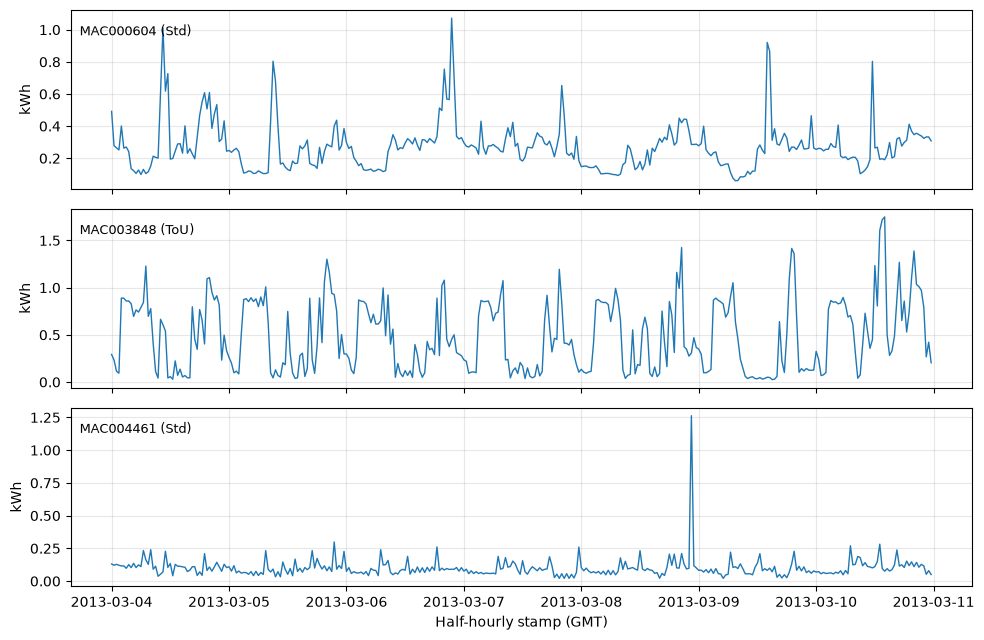

In [10]:
week = df[
    df["LCLid"].isin(households)
    & df["date"].between("2013-03-04", "2013-03-10")
]
print(
    f"Figure 1: {week['date'].min()} to {week['date'].max()}, households "
    f"{', '.join(households)}"
)

fig, axes = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True)
for ax, (household, rows) in zip(axes, week.groupby("LCLid")):
    values = rows[reading_columns].to_numpy().ravel()
    times = pd.date_range(
        rows["date"].iloc[0], periods=len(values), freq="30min"
    )
    ax.plot(times, values, linewidth=1)
    ax.set_ylabel("kWh")
    ax.text(
        0.01,
        0.92,
        f"{household} ({rows['tariff_group'].iloc[0]})",
        transform=ax.transAxes,
        va="top",
        fontsize=9,
    )
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Half-hourly stamp (GMT)")
fig.tight_layout()
os.makedirs("outputs", exist_ok=True)
fig.savefig("outputs/figure_1_data_sample.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 1.** One week of half-hourly readings, 2013-03-04 to 2013-03-10 (Monday to Sunday, in the training months, GMT stamps), for the three households drawn with seed 42, each named by its published pseudonymous `LCLid` and its tariff group. The three differ in level and in shape. MAC000604 has short peaks above a steady base, MAC003848 (the time-of-use group) switches between a low level and a high one through each day, and MAC004461 stays low apart from one short spike. One model has to forecast all three kinds.

In [11]:
def to_cube(frame, columns):
    """Return the household IDs, the dates and the readings as an array of
    shape (households, days, len(columns)), from a frame with one row per
    household-day, sorted by household and then date, every household
    holding the same dates."""
    ids = frame["LCLid"].drop_duplicates().to_numpy()
    if len(frame) % len(ids):
        raise ValueError("the households hold different numbers of days")
    n_days = len(frame) // len(ids)
    who = frame["LCLid"].to_numpy().reshape(len(ids), n_days)
    when = frame["date"].to_numpy().reshape(len(ids), n_days)
    if (who != ids[:, None]).any() or (when != when[0]).any():
        raise ValueError(
            "each household needs the same dates, in one block of rows"
        )
    if list(ids) != sorted(ids) or list(when[0]) != sorted(when[0]):
        raise ValueError("the rows must be sorted by household and then date")
    values = (
        frame[columns]
        .to_numpy(dtype=float)
        .reshape(len(ids), n_days, len(columns))
    )
    return ids, when[0].copy(), values

In [12]:
def cut_window(series, target_day, input_days=7, per_day=48):
    """Return one window from a household's readings in time order: the
    input, the input_days * per_day readings before the target day, shaped
    (steps, 1), and the target, the per_day readings of the target day."""
    start = (target_day - input_days) * per_day
    middle = target_day * per_day
    end = middle + per_day
    if start < 0 or end > len(series):
        raise ValueError("the window must lie inside the series")
    x = np.array(series[start:middle], dtype=float).reshape(-1, 1)
    y = np.array(series[middle:end], dtype=float)
    return x, y

In [13]:
households_all, days, cube = to_cube(df, reading_columns)
print(f"Readings as an array of households, days and half-hours: {cube.shape}")

target = 7
x, y = cut_window(cube[0].ravel(), target)
print(f"\nOne window for {households_all[0]}:")
print(
    f"  input, {days[target - 7]} 00:00 to {days[target - 1]} 23:30: shape "
    f"{torch.from_numpy(x).float().shape}"
)
print(
    f"  target (the labels), {days[target]} 00:00 to {days[target]} 23:30: "
    f"shape {torch.from_numpy(y).float().shape}"
)
print("  last six input readings:", np.round(x[-6:, 0], 3))
print("  target readings:", np.round(y, 3))

Readings as an array of households, days and half-hours: (1000, 365, 48)

One window for MAC000006:
  input, 2013-01-01 00:00 to 2013-01-07 23:30: shape torch.Size([336, 1])
  target (the labels), 2013-01-08 00:00 to 2013-01-08 23:30: shape torch.Size([48])
  last six input readings: [0.024 0.    0.    0.    0.    0.   ]
  target readings: [0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
 0.    0.    0.024 0.044 0.044 0.044 0.044 0.03  0.    0.    0.    0.
 0.    0.    0.144 0.067 0.067 0.06  0.043 0.115 0.078 0.037 0.073 0.036
 0.083 0.085 0.088 0.066 0.037 0.071 0.015 0.049 0.014 0.05  0.047 0.299]


**Inputs and labels.** A forecast has no class labels. Its labels are its targets: the 48 half-hourly readings of the day after the input week. One window is a household's 336 readings over seven days, shaped (336, 1) because each step carries one feature, the reading in kWh. Its target is shaped (48,) because the model forecasts all 48 readings at once. The array above holds every reading as households by days by half-hours, so windows can be cut from it when needed rather than stored. Task 3 cuts the windows for every household and target day, counts them in each split, and fits the scaler on the training months only. The file loads as float64, and the models will train in float32.

**Naive forecasts on the validation months.** Three naive forecasts show the level a model has to beat. Each forecasts a target day at 00:00 from earlier days only: the same half-hour yesterday, the same half-hour last week, and the mean of the previous 7 days at each half-hour. They are scored here on the validation months (1 Sep to 31 Oct 2013) only. The test months stay unread until Task 5.

The metrics:

- MAE in kWh per half-hour: the mean absolute error over every household and half-hour;
- MAE divided by mean use: the MAE over the mean reading, so that months with different levels of use can be compared;
- MASE per household: each household's MAE divided by the MAE of the same half-hour yesterday on that household's training months (1 Jan to 31 Aug 2013), given as the mean and the median over households. This is the seasonal form of the mean absolute scaled error, with a season of one day (Hyndman & Koehler, 2006; Hyndman & Athanasopoulos, 2021, sec. 5.8);
- RMSE in kWh per half-hour, which weighs large errors more.

In [14]:
def naive_forecasts(cube, target_days):
    """Return the three naive forecasts for each target day, made from
    earlier days only, each shaped (households, len(target_days), 48): the
    same half-hour yesterday, the same half-hour last week, and the mean of
    the previous 7 days at each half-hour."""
    target_days = np.asarray(target_days)
    if target_days.min() < 7:
        raise ValueError("every target day needs seven earlier days")
    weeks = zip(target_days - 7, target_days)
    return {
        "same half-hour yesterday": cube[:, target_days - 1],
        "same half-hour last week": cube[:, target_days - 7],
        "mean of the previous 7 days": np.stack(
            [cube[:, first:day].mean(axis=1) for first, day in weeks], axis=1
        ),
    }

In [15]:
def insample_scale(cube, days, lag=48):
    """Return each household's MASE scale: the MAE of the same half-hour
    yesterday inside the given consecutive days, every reading against the
    one lag readings before it."""
    days = np.asarray(days)
    if np.any(np.diff(days) != 1):
        raise ValueError("the days must be consecutive")
    series = cube[:, days].reshape(len(cube), -1)
    return np.abs(series[:, lag:] - series[:, :-lag]).mean(axis=1)

In [16]:
def forecast_scores(actual, forecast, scale):
    """Return MAE, MAE divided by mean use, MASE per household (mean and
    median) and RMSE for forecasts against actual readings, both shaped
    (households, days, 48). scale holds each household's MASE scale; a
    household whose scale is zero has no MASE and is left out of it."""
    error = forecast - actual
    mae = np.abs(error).mean()
    household_mae = np.abs(error).mean(axis=(1, 2))
    mase = household_mae[scale > 0] / scale[scale > 0]
    return {
        "MAE (kWh per half-hour)": mae,
        "MAE divided by mean use": mae / actual.mean(),
        "MASE per household, mean": mase.mean() if mase.size else np.nan,
        "MASE per household, median": np.median(mase) if mase.size else np.nan,
        "RMSE (kWh per half-hour)": np.sqrt((error**2).mean()),
    }

In [17]:
day_split = assign_split(days)
training_days = np.flatnonzero(day_split == "training")
validation_days = np.flatnonzero(day_split == "validation")

scale = insample_scale(cube, training_days)
actual = cube[:, validation_days]
naive = naive_forecasts(cube, validation_days)
naive_table = pd.DataFrame(
    {
        name: forecast_scores(actual, forecast, scale)
        for name, forecast in naive.items()
    }
).T

print(
    f"Validation months: {days[validation_days[0]]} to "
    f"{days[validation_days[-1]]}, {len(validation_days)} target days, "
    f"{len(actual):,} households"
)
print(
    f"Mean use on the validation months: {actual.mean():.4f} kWh per half-hour"
)
print(
    f"MASE scale from the training months, {days[training_days[0]]} to "
    f"{days[training_days[-1]]}: households with a zero scale "
    f"{int((scale == 0).sum())}\n"
)
print(naive_table.round(4).to_string())

Validation months: 2013-09-01 to 2013-10-31, 61 target days, 1,000 households
Mean use on the validation months: 0.1955 kWh per half-hour
MASE scale from the training months, 2013-01-01 to 2013-08-31: households with a zero scale 0

                             MAE (kWh per half-hour)  MAE divided by mean use  MASE per household, mean  MASE per household, median  RMSE (kWh per half-hour)
same half-hour yesterday                      0.1147                   0.5864                    0.9534                      0.9572                    0.2434
same half-hour last week                      0.1165                   0.5961                    0.9688                      0.9572                    0.2451
mean of the previous 7 days                   0.0962                   0.4922                    0.7994                      0.7934                    0.1911


In [18]:
group = (
    df.groupby("LCLid")["tariff_group"]
    .first()
    .reindex(households_all)
    .to_numpy()
)
by_group = {}
for name, forecast in naive.items():
    row = {}
    for metric in [
        "MAE divided by mean use",
        "MAE (kWh per half-hour)",
        "MASE per household, median",
    ]:
        for tariff in ["Std", "ToU"]:
            mine = group == tariff
            row[(metric, tariff)] = forecast_scores(
                actual[mine], forecast[mine], scale[mine]
            )[metric]
    by_group[name] = row

print(
    "Mean use on the validation months, kWh per half-hour: "
    + ", ".join(
        f"{tariff} {actual[group == tariff].mean():.4f} "
        f"({(group == tariff).sum()} households)"
        for tariff in ["Std", "ToU"]
    )
)
print(pd.DataFrame(by_group).T.round(4).to_string())

Mean use on the validation months, kWh per half-hour: Std 0.2032 (781 households), ToU 0.1680 (219 households)
                            MAE divided by mean use         MAE (kWh per half-hour)         MASE per household, median        
                                                Std     ToU                     Std     ToU                        Std     ToU
same half-hour yesterday                     0.5812  0.6088                  0.1181  0.1023                     0.9590  0.9534
same half-hour last week                     0.5916  0.6152                  0.1202  0.1034                     0.9614  0.9460
mean of the previous 7 days                  0.4883  0.5089                  0.0992  0.0855                     0.7944  0.7902


**What the naive forecasts show.** On the validation months the mean of the previous 7 days is the best of the three on every measure: MAE 0.0962 kWh per half-hour, or 0.4922 of mean use, against 0.1147 for the same half-hour yesterday and 0.1165 for the same half-hour last week. Its MASE per household has a mean of 0.7994 and a median of 0.7934, both below 1. RMSE runs at about twice the MAE for all three, a sign of occasional large errors. These figures are the level the two models have to beat. The same three forecasts are scored on the test months once, in Task 5, beside the models.

By tariff group, the naive forecasts err a little more relative to use for the time-of-use group: 0.5089 of mean use against 0.4883 for the mean of the previous 7 days. That group also uses less (0.1680 against 0.2032 kWh per half-hour), so the gap alone does not show an effect of the price signals.

**The anomaly list.** Before any model uses the data, every anomaly found in it is listed here. Each rule was written from the training and validation months only, then applied to every month, so the test months carry the same flags, and no test-month count is printed until after the rulings. No row is removed: the flags sit in a separate frame beside `df`, one row per household-day with a reason column, so that results can later be reported with and without the flagged households. That follows the advice to flag each suspect reading by its type and to report results with and without the outliers that remain (Van den Broeck et al., 2005, Documentation and Reporting section). The table gives counts for the training and validation months.

In [19]:
def run_lengths(series):
    """Return, for each value along the last axis of a 2-D array, the length
    of the run of equal consecutive values it belongs to."""
    lengths = np.empty(np.shape(series), dtype=int)
    for i, row in enumerate(np.asarray(series)):
        run = np.cumsum(np.r_[True, row[1:] != row[:-1]]) - 1
        lengths[i] = np.bincount(run)[run]
    return lengths

In [20]:
def artefact_mask(values, places=3):
    """Return True for each reading with more than `places` decimal places,
    such as the float32 rounding 1.4529999 in a file whose readings
    otherwise have three."""
    scaled = np.asarray(values) * 10**places
    return np.abs(scaled - np.rint(scaled)) > 1e-6

In [21]:
def summer_time_mask(dates, per_day=48):
    """Return True for each of a date's half-hourly GMT stamps that falls in
    British Summer Time, shaped (dates, per_day). The clocks go forward at
    01:00 GMT on the last Sunday in March and back at 01:00 GMT (02:00
    summer time) on the last Sunday in October."""
    days = pd.to_datetime(pd.Series(dates), format="%Y-%m-%d")
    stamps = days.to_numpy()[:, None] + np.arange(per_day) * np.timedelta64(
        24 * 60 // per_day, "m"
    )
    mask = np.zeros(stamps.shape, dtype=bool)
    for year in days.dt.year.unique():
        ends = []
        for month in (3, 10):
            last = pd.Timestamp(year, month, 31)
            sunday = last - pd.Timedelta(days=(last.dayofweek + 1) % 7)
            ends.append(np.datetime64(sunday + pd.Timedelta(hours=1)))
        mask |= (stamps >= ends[0]) & (stamps < ends[1])
    return mask

In [22]:
def crosses_change(change_day, input_days=7):
    """Return True for each target day whose input week or own day holds a
    clock change, so that its input and its target sit an hour apart in the
    stamps: the change day and the input_days days after it. change_day is
    True on each clock-change day."""
    change_day = np.asarray(change_day, dtype=bool)
    crossing = np.zeros(len(change_day), dtype=bool)
    for day in np.flatnonzero(change_day):
        last = day + input_days + 1
        crossing[day:last] = True
    return crossing

In [23]:
def rise_halfway(profile, night=(0, 12), morning=(10, 22)):
    """Return the index of the first half-hour in the morning window at or
    above the midpoint between the profile's night low and its morning high,
    or None if there is none."""
    profile = np.asarray(profile)
    night_start, night_end = night
    first, last = morning
    low = profile[night_start:night_end].min()
    high = profile[first:last].max()
    above = np.flatnonzero(profile[first:last] >= (low + high) / 2)
    return int(first + above[0]) if above.size else None

In [24]:
def month_change_mask(monthly, factor=3.0):
    """Return True for each household-month whose mean use is at least
    factor times, or at most 1/factor of, the household's mean in the month
    before. monthly is shaped (households, months); the first month has no
    month before, and two months with no use are no change."""
    monthly = np.asarray(monthly, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = monthly[:, 1:] / monthly[:, :-1]
    change = (ratio >= factor) | (ratio <= 1 / factor)
    return np.concatenate(
        [np.zeros((len(monthly), 1), dtype=bool), change], axis=1
    )

In [25]:
def anomaly_counts(masks, day_split, splits):
    """Return a table, one row per anomaly, of the readings, household-days
    and households each mask flags in each named split. Each mask is shaped
    (households, days, readings a day), and day_split names the split of
    each day."""
    rows = {}
    for name, mask in masks.items():
        row = {}
        for split in splits:
            part = mask[:, np.asarray(day_split) == split]
            row[(split, "readings")] = int(part.sum())
            row[(split, "household-days")] = int(part.any(axis=2).sum())
            row[(split, "households")] = int(part.any(axis=(1, 2)).sum())
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")

In [26]:
def flag_reasons(flags):
    """Return, for each row of a frame of True or False flag columns, the
    names of the flags it carries joined by "; ", or an empty string."""
    names = [
        np.where(flags[column].to_numpy(), column, "")
        for column in flags.columns
    ]
    return pd.Series(
        ["; ".join(name for name in row if name) for row in zip(*names)],
        index=flags.index,
    )

In [27]:
# Every threshold below is read from the training and validation months only.
# Rule 6 comes from the manifest, because the pipeline rounds every reading
# before it writes the working file.
tv = np.isin(day_split, ["training", "validation"])
day = cube.shape[2]
seen = cube[:, tv]
high_line = np.percentile(seen, 99.99)
print(
    "99.99th percentile of the training and validation readings: "
    f"{high_line:.4f} kWh; the highest reading there is {seen.max():.4f} kWh"
)

month = pd.to_datetime(pd.Series(days)).dt.month.to_numpy()
monthly = np.stack(
    [cube[:, month == m].mean(axis=(1, 2)) for m in range(1, 13)], axis=1
)
seen_months = np.unique(month[tv])
with np.errstate(divide="ignore", invalid="ignore"):
    ratio = monthly[:, seen_months[1:] - 1] / monthly[:, seen_months[:-1] - 1]
factor = np.exp(np.abs(np.log(ratio[np.isfinite(ratio) & (ratio > 0)])))
print(
    "Factor of month-on-month change in use, training and validation months, "
    "at the 50th, 90th, 99th and 99.5th percentiles: "
    + ", ".join(f"{v:.2f}" for v in np.percentile(factor, [50, 90, 99, 99.5]))
)
for name in ["training", "validation"]:
    lowest = np.sort(cube[:, day_split == name].mean(axis=(1, 2)))[:5]
    print(
        f"The five lowest household means, {name} months, kWh per half-hour: "
        + ", ".join(f"{v:.4f}" for v in lowest)
    )

summer = summer_time_mask(days)
change_day = summer.any(axis=1) & ~summer.all(axis=1)
first_change, second_change = days[change_day]
rounding = manifest["Rounding"][0].set_index("Item")["Value"]
long_count = rounding["Readings in the download with more than three decimals"]
long_example = rounding["The first of them in the download"].split(", ")[-1]
rules = {
    "zero run of a day or more": (
        f"{day} or more zero readings in a row, along the household's whole "
        "2013 series"
    ),
    "high reading": (
        f"a reading above {high_line:.4f} kWh, the 99.99th percentile above"
    ),
    "same non-zero reading for a day or more": (
        f"{day} or more equal non-zero readings in a row"
    ),
    "very low use": (
        "a household whose mean over a split's months is below 0.01 kWh per "
        "half-hour, flagged on that split's days"
    ),
    "sharp change in monthly use": (
        "a calendar month whose mean use is at least 3 times, or at most a "
        "third of, the household's mean in the month before"
    ),
    "float32 artefact in the published text": (
        "a reading with more than three decimal places, as the publisher's "
        f"text holds {long_count} of them, such as {long_example}; the "
        "pipeline rounds every reading to three decimals, to the nearest, and "
        f"changed {steps['Step 7, readings the rounding changed']} in this "
        "sample, so this count checks that the working file holds none"
    ),
    "summer one-hour shift in the stamps": (
        f"a stamp from 01:00 GMT on {first_change} to 01:00 GMT on "
        f"{second_change}, British Summer Time"
    ),
    "input week crosses a clock change": (
        "every reading of a target day from a clock-change day to seven days "
        "after it"
    ),
}
print("\nThe rules:")
for number, (name, rule) in enumerate(rules.items(), 1):
    print(f"{number}. {name}: {rule}")

99.99th percentile of the training and validation readings: 4.8548 kWh; the highest reading there is 8.2040 kWh


Factor of month-on-month change in use, training and validation months, at the 50th, 90th, 99th and 99.5th percentiles: 1.08, 1.38, 2.48, 3.17
The five lowest household means, training months, kWh per half-hour: 0.0014, 0.0019, 0.0078, 0.0214, 0.0281
The five lowest household means, validation months, kWh per half-hour: 0.0000, 0.0007, 0.0051, 0.0095, 0.0171

The rules:
1. zero run of a day or more: 48 or more zero readings in a row, along the household's whole 2013 series
2. high reading: a reading above 4.8548 kWh, the 99.99th percentile above
3. same non-zero reading for a day or more: 48 or more equal non-zero readings in a row
4. very low use: a household whose mean over a split's months is below 0.01 kWh per half-hour, flagged on that split's days
5. sharp change in monthly use: a calendar month whose mean use is at least 3 times, or at most a third of, the household's mean in the month before
6. float32 artefact in the published text: a reading with more than three decimal place

In [28]:
# The weekday morning rise before and after each clock change, and a pair of
# fortnights with no change between them as a control. Around 31 Mar each
# fortnight stands a week clear of the change; after 27 Oct the validation
# months leave only four weekdays.
weekday = pd.to_datetime(pd.Series(days)).dt.dayofweek.to_numpy() < 5
periods = [
    (
        "31 Mar, training months",
        ("2013-03-11", "2013-03-22"),
        ("2013-04-08", "2013-04-19"),
    ),
    (
        "27 Oct, validation months",
        ("2013-10-14", "2013-10-25"),
        ("2013-10-28", "2013-10-31"),
    ),
    (
        "no change, training months",
        ("2013-02-04", "2013-02-15"),
        ("2013-02-18", "2013-03-01"),
    ),
]
clock_rows = []
for label, before, after in periods:
    row = [label]
    for first, last in (before, after):
        pick = weekday & (days >= first) & (days <= last)
        row += [
            f"{first} to {last}",
            stamps[rise_halfway(cube[:, pick].mean(axis=(0, 1)))],
        ]
    clock_rows.append(row)
clock = pd.DataFrame(
    clock_rows,
    columns=[
        "clock change",
        "weekdays before",
        "half-way before",
        "weekdays after",
        "half-way after",
    ],
)
print(
    "Half-way up the weekday morning rise, as a GMT stamp, all households "
    "averaged:"
)
print(clock.to_string(index=False))

Half-way up the weekday morning rise, as a GMT stamp, all households averaged:
              clock change          weekdays before half-way before           weekdays after half-way after
   31 Mar, training months 2013-03-11 to 2013-03-22           07:00 2013-04-08 to 2013-04-19          06:00
 27 Oct, validation months 2013-10-14 to 2013-10-25           06:00 2013-10-28 to 2013-10-31          07:00
no change, training months 2013-02-04 to 2013-02-15           07:00 2013-02-18 to 2013-03-01          07:00


In [29]:
runs = run_lengths(cube.reshape(len(cube), -1)).reshape(cube.shape)
low = np.zeros(cube.shape[:2], dtype=bool)
for name in ["training", "validation", "test"]:
    part = day_split == name
    low[:, part] = (cube[:, part].mean(axis=(1, 2)) < 0.01)[:, None]
sharp = month_change_mask(monthly)[:, month - 1]
crossing = crosses_change(change_day)

masks = {
    "zero run of a day or more": (cube == 0) & (runs >= day),
    "high reading": cube > high_line,
    "same non-zero reading for a day or more": (cube != 0) & (runs >= day),
    "very low use": np.repeat(low[:, :, None], day, axis=2),
    "sharp change in monthly use": np.repeat(sharp[:, :, None], day, axis=2),
    "float32 artefact in the published text": artefact_mask(cube),
    "summer one-hour shift in the stamps": np.broadcast_to(summer, cube.shape),
    "input week crosses a clock change": np.broadcast_to(
        crossing[None, :, None], cube.shape
    ),
}
flags = pd.DataFrame(
    {name: mask.any(axis=2).ravel() for name, mask in masks.items()},
    index=df.index,
)
flags["reasons"] = flag_reasons(flags)
print(
    f"Flags: {len(flags):,} household-days, the same rows as the working "
    f"file, none removed ({len(df):,} rows in df)"
)
print(f"Flag columns: {', '.join(flags.columns)}")

Flags: 365,000 household-days, the same rows as the working file, none removed (365,000 rows in df)
Flag columns: zero run of a day or more, high reading, same non-zero reading for a day or more, very low use, sharp change in monthly use, float32 artefact in the published text, summer one-hour shift in the stamps, input week crosses a clock change, reasons


In [30]:
anomaly_table = anomaly_counts(masks, day_split, ["training", "validation"])
print(anomaly_table.map("{:,}".format).to_string())

print()
for name in ["training", "validation"]:
    part = day_split == name
    flagged = np.zeros(len(cube), dtype=bool)
    for key in list(masks)[:5]:
        flagged |= masks[key][:, part].any(axis=(1, 2))
    print(
        f"Households with any of anomalies 1 to 5 in the {name} months: "
        f"{int(flagged.sum())}"
    )

                                          training                           validation                          
                                          readings household-days households   readings household-days households
zero run of a day or more                   41,757            917         15     13,040            285         11
high reading                                 1,372            659         27         88             61          7
same non-zero reading for a day or more      3,031             79          2        165              5          1
very low use                                34,992            729          3     11,712            244          4
sharp change in monthly use                 69,504          1,448         28     30,672            639         18
float32 artefact in the published text           0              0          0          0              0          0
summer one-hour shift in the stamps      7,390,000        154,000      1,000  2,690,000 

Households with any of anomalies 1 to 5 in the validation months: 32


In [31]:
pipeline_steps = manifest["Pipeline steps"][0].set_index("Step")["Count"]
dropped = pipeline_steps.loc[
    [
        'Step 1, "Null" readings',
        "Step 1, rows off the half-hour grid",
        'Step 1, rows both "Null" and off the grid',
        "Step 2, exact duplicates dropped",
    ]
]
print(
    "Rows the pipeline dropped before writing the working file, whole "
    "download (manifest):"
)
print(dropped.to_string())
print(
    "\nTariff half-hours that the move to GMT leaves with two tariff rows or "
    "none (manifest):"
)
print(manifest["Price signals"][1].to_string(index=False))
print(
    "\nThe working file holds none of the dropped rows, so it cannot count "
    "them by month."
)

Rows the pipeline dropped before writing the working file, whole download (manifest):
Step
Step 1, "Null" readings                        5,560
Step 1, rows off the half-hour grid            5,560
Step 1, rows both "Null" and off the grid      5,560
Step 2, exact duplicates dropped             115,453

Tariff half-hours that the move to GMT leaves with two tariff rows or none (manifest):
      GMT half-hour Tariff rows         Values
2013-03-31 01:00:00           2 Normal, Normal
2013-03-31 01:30:00           2 Normal, Normal
2013-10-27 01:00:00           0           none
2013-10-27 01:30:00           0           none

The working file holds none of the dropped rows, so it cannot count them by month.


**Data quality notes.** What the anomaly list shows, with its counts from the table above. Every raw row stays in `df`, and the flags record where each anomaly falls.

1. **Zero run of a day or more.** 15 households in the training months and 11 in the validation months hold a day or more of zero readings in a row. The data does not say whether the household was away or its smart meter recorded nothing.
2. **High reading.** A reading above 4.8548 kWh in a half-hour, the 99.99th percentile of the training and validation readings, comes from 27 households in the training months and 7 in the validation months; the highest is 8.2040 kWh. Nothing in the data marks these as faults, so they may be real heavy use. Large readings weigh on RMSE more than on MAE.
3. **Same non-zero reading for a day or more.** 2 households in the training months and 1 in the validation months repeat one non-zero reading for a day or more, which may be a stuck smart meter or a small steady load.
4. **Very low use.** 3 households in the training months and 4 in the validation months use less than 0.01 kWh per half-hour on average. In the training months the five lowest means jump from 0.0078 to 0.0214. The data does not say whether these households were away or their smart meters recorded little.
5. **Sharp change in monthly use.** 28 households in the training months and 18 in the validation months have a month at least 3 times, or at most a third of, the month before. The factor 3 lies between the 99th and 99.5th percentiles of month-on-month change in those months (2.48 and 3.17). Across such a change, the input week can show a different level of use from the day being forecast.
6. **Float32 artefact in the published text.** The publisher's own file holds 1,015,466 readings with more than three decimal places, such as 1.4529999, which looks like a three-decimal reading stored as float32. The pipeline rounds every reading to three decimals, to the nearest, which changed 115,323 readings in this sample by at most 0.0000005 kWh, so the table above counts none in the working file. The download itself is kept unchanged.
7. **Summer one-hour shift in the stamps.** The stamps behave as GMT all year: the weekday morning rise is half-way up at 07:00 before 31 Mar, at 06:00 after it, and back at 07:00 after 27 Oct, while the control fortnights show no move. So from 2013-03-31 to 2013-10-27 the households' routines sit an hour earlier in the stamps (154,000 household-days in the training months and 57,000 in the validation months). The two change dates fit the UK rule as GOV.UK gives it: "In the UK the clocks go forward 1 hour at 1am on the last Sunday in March, and back 1 hour at 2am on the last Sunday in October" (GOV.UK, 2025).
8. **Input week crosses a clock change.** On the change day and the seven days after it, a window's input week and its target day sit an hour apart in the stamps: 8,000 household-days in the training months and 5,000 in the validation months.

61 households in the training months and 32 in the validation months carry at least one of anomalies 1 to 5.

**Before the working file.** The pipeline dropped 5,560 "Null" readings (the same rows are stamped off the half-hour grid) and 115,453 exact duplicates, counted over the whole download, so the working file cannot count them by month. Moving the tariff file to GMT gives two half-hours on 2013-03-31 two tariff rows, both Normal, and two on 2013-10-27 none, so 27 Oct's price signal rests on its other half-hours. The pipeline also rounded every reading to three decimals (note 6).

How each anomaly is treated (flag, keep or exclude) is settled before any model trains, and Task 3 applies it. These options rest on the data cleaning framework of Van den Broeck et al. (2005): "The options are limited to correcting, deleting, or leaving unchanged" (Treatment Phase section). Every flagged reading stays unchanged in `df`. An exclusion, if one is ruled, applies to the analysis only, and results are then reported with and without the excluded readings.

## Task 3: Implement a Baseline Deep Learning Model

**Goal.** Apply the anomaly rulings, cut the windows and fit the scaler, then define the baseline model (the LSTM) and train it over three seeds. Each run keeps its best epoch, saves it and reloads it, so the forecasts in Task 5 come from the weights the log names.

**Applying the anomaly rulings.** Paddy ruled on the anomaly list above, every row as recommended. The treatment follows the steps of Van den Broeck et al. (2005): find each anomaly, diagnose it, then treat it and record the treatment. Here every raw row is kept and the anomalies are flagged.

- Both models train on every household as recorded, the flagged ones included, because a forecaster for real households has to cope with odd ones too.
- Five flags stay as flag columns beside `df`: zero run of a day or more, high reading, same non-zero reading for a day or more, very low use, and sharp change in monthly use. A high reading is kept as recorded, with no clipping, because clipping would change the targets.
- The flag input week crosses a clock change also stays as a column, and the failure-case hunt in Task 5 looks there first.
- The float32 artefact needs no column, because the pipeline rounded every reading, and the summer one-hour shift in the stamps is kept as published and stated in note 7.
- 27 Oct gets a flag for the time-of-use group, because the move of the tariff file to GMT leaves that day's price label resting on fewer than its 48 half-hours.
- Test results are reported twice, with every household and without the flagged households: the households that carry any of the first five flags in the training or validation months. The cell below counts them and fixes that set from the training and validation months only.

In [32]:
def flagged_households(masks, names, day_split, splits):
    """Return True for each household that carries any of the named flags on
    a day in the named splits. Each mask is shaped (households, days,
    readings a day), and day_split names the split of each day."""
    days = np.isin(np.asarray(day_split), splits)
    flagged = np.zeros(len(masks[names[0]]), dtype=bool)
    for name in names:
        flagged |= masks[name][:, days].any(axis=(1, 2))
    return flagged

In [33]:
first_five = list(masks)[:5]
ruled = first_five + ["input week crosses a clock change"]
oct_27 = "27 Oct price label rests on 46 half-hours"
flag_columns = flags[ruled].copy()
flag_columns[oct_27] = (df["tariff_group"] == "ToU") & (
    df["date"] == "2013-10-27"
)
flag_columns["reasons"] = flag_reasons(flag_columns[ruled + [oct_27]])
print(f"Flag columns: {', '.join(flag_columns.columns)}")

gaps = manifest["Price signals"][1]
missing = int(
    (gaps["GMT half-hour"].str.startswith("2013-10-27"))
    .mul(gaps["Tariff rows"] == "0")
    .sum()
)
print(
    f"27 Oct price label: {int(flag_columns[oct_27].sum())} household-days, "
    "the time-of-use group on 2013-10-27, whose label rests on "
    f"{day - missing} of the day's {day} half-hours"
)

flagged = flagged_households(
    masks, first_five, day_split, ["training", "validation"]
)
test_only = (
    flagged_households(masks, first_five, day_split, ["test"]) & ~flagged
)
print(
    "\nHouseholds with any of flags 1 to 5 in the training or validation "
    f"months: {int(flagged.sum())}; test results are reported with all "
    f"{len(flagged):,} households and without these {int(flagged.sum())}"
)
print(
    "Households with a flag 1 to 5 only in the test months: "
    f"{int(test_only.sum())}, kept in both sets, as the ruled set is the "
    "one fixed before the test months are read"
)
print("The flagged households:")
for start in range(0, int(flagged.sum()), 8):
    stop = start + 8
    print("  " + ", ".join(households_all[flagged][start:stop]))

print("\nThe ruled flags in every split, now the rulings are applied:")
ruled_masks = {name: masks[name] for name in ruled}
ruled_table = anomaly_counts(
    ruled_masks, day_split, ["training", "validation", "test"]
)
print(ruled_table.map("{:,}".format).to_string())

Flag columns: zero run of a day or more, high reading, same non-zero reading for a day or more, very low use, sharp change in monthly use, input week crosses a clock change, 27 Oct price label rests on 46 half-hours, reasons
27 Oct price label: 219 household-days, the time-of-use group on 2013-10-27, whose label rests on 46 of the day's 48 half-hours

Households with any of flags 1 to 5 in the training or validation months: 74; test results are reported with all 1,000 households and without these 74
Households with a flag 1 to 5 only in the test months: 15, kept in both sets, as the ruled set is the one fixed before the test months are read
The flagged households:
  MAC000049, MAC000260, MAC000307, MAC000320, MAC000418, MAC000891, MAC001095, MAC001212
  MAC001309, MAC001312, MAC001550, MAC001655, MAC001698, MAC001715, MAC001739, MAC001751
  MAC001758, MAC002007, MAC002042, MAC002192, MAC002231, MAC002388, MAC002400, MAC002418
  MAC002434, MAC002465, MAC002564, MAC002616, MAC002627, MAC

                                        training                           validation                               test                          
                                        readings household-days households   readings household-days households readings household-days households
zero run of a day or more                 41,757            917         15     13,040            285         11   14,530            317         14
high reading                               1,372            659         27         88             61          7      426            205         16
same non-zero reading for a day or more    3,031             79          2        165              5          1        0              0          0
very low use                              34,992            729          3     11,712            244          4    8,784            183          3
sharp change in monthly use               69,504          1,448         28     30,672            639         18   30,6

**Windows and the scaler.** Each window is one household and one target day: the 336 readings of the seven days before that day as the input, and the day's 48 readings as the target. The input week may reach back into the months before, but never before 1 Jan 2013, so the first target day is 8 Jan. Windows are not stored. The `Dataset` cuts each one from the household's series when the `DataLoader` asks for it.

One scaler, the mean and standard deviation of every reading in the training months, is applied to inputs and targets alike. The validation and test months play no part in it, so nothing from them reaches training. With one linear scale for every reading, the L1 loss on scaled values is the MAE in kWh divided by the standard deviation, so the loss the models train on and the headline metric rank forecasts the same way.

In [34]:
def fit_scaler(cube, days):
    """Return the mean and standard deviation of every reading in the given
    days, from an array shaped (households, days, readings a day)."""
    values = np.asarray(cube)[:, np.asarray(days)]
    return float(values.mean()), float(values.std())

In [35]:
def window_pairs(n_households, target_days):
    """Return one (household index, target day) row per window: every target
    day of the first household, then of the second, and so on."""
    target_days = np.asarray(target_days)
    households = np.repeat(np.arange(n_households), len(target_days))
    return np.column_stack([households, np.tile(target_days, n_households)])

In [36]:
class WindowDataset(Dataset):
    """Windows cut on demand from each household's readings in time order:
    the input_days before a target day in, the target day's readings out,
    both scaled with one mean and standard deviation."""

    def __init__(self, series, pairs, mean, std, input_days=7, per_day=48):
        """Keep the readings, shaped (households, readings) in kWh, a scaled
        float32 copy of them, and the (household, target day) pairs."""
        self.raw = np.asarray(series, dtype=float)
        self.scaled = torch.as_tensor(
            (self.raw - mean) / std, dtype=torch.float32
        )
        self.pairs = np.asarray(pairs)
        self.mean, self.std = mean, std
        self.input_days, self.per_day = input_days, per_day

    def __len__(self):
        """Return the number of windows."""
        return len(self.pairs)

    def __getitem__(self, index):
        """Return one window's scaled input, shaped (steps, 1), and its
        scaled target."""
        household, day = self.pairs[index]
        start = (day - self.input_days) * self.per_day
        steps = self.input_days * self.per_day
        end = start + steps + self.per_day
        window = self.scaled[household, start:end]
        return window[:steps].unsqueeze(-1), window[steps:]

    def actual(self):
        """Return every window's target in kWh, shaped (windows, per_day)."""
        rows, days = self.pairs[:, 0], self.pairs[:, 1]
        columns = days[:, None] * self.per_day + np.arange(self.per_day)
        return self.raw[rows[:, None], columns]

In [37]:
target_days = {
    "training": training_days[training_days >= 7],
    "validation": validation_days,
    "test": np.flatnonzero(day_split == "test"),
}
mean, std = fit_scaler(cube, training_days)
print(
    f"Scaler from the training months, {days[training_days[0]]} to "
    f"{days[training_days[-1]]}: mean {mean:.4f} kWh, standard deviation "
    f"{std:.4f} kWh, from {cube[:, training_days].size:,} readings\n"
)

series = cube.reshape(len(cube), -1)
datasets = {
    name: WindowDataset(series, window_pairs(len(cube), chosen), mean, std)
    for name, chosen in target_days.items()
}
# The test windows are counted from their dates alone; their readings are
# first scored in Task 5.
for name, chosen in target_days.items():
    span = ""
    if name != "test":
        span = f", {days[chosen[0]]} to {days[chosen[-1]]}"
    print(
        f"{name}: {len(chosen)} target days{span}, "
        f"{len(datasets[name]):,} windows"
    )

x, y = datasets["training"][0]
print(
    f"\nOne training window from the Dataset: x {x.shape} {x.dtype}, "
    f"y {y.shape} {y.dtype}"
)
cx, cy = cut_window(series[0], target_days["training"][0])
match = np.allclose(x.numpy()[:, 0] * std + mean, cx[:, 0], atol=1e-5)
match &= np.allclose(y.numpy() * std + mean, cy, atol=1e-5)
print(f"The window scaled back to kWh matches cut_window: {match}")

Scaler from the training months, 2013-01-01 to 2013-08-31: mean 0.2158 kWh, standard deviation 0.3112 kWh, from 11,664,000 readings



training: 236 target days, 2013-01-08 to 2013-08-31, 236,000 windows
validation: 61 target days, 2013-09-01 to 2013-10-31, 61,000 windows
test: 61 target days, 61,000 windows

One training window from the Dataset: x torch.Size([336, 1]) torch.float32, y torch.Size([48]) torch.float32
The window scaled back to kWh matches cut_window: True


**The baseline model (the LSTM).** `ForecastRNN` is one class for both models, and its `cell` argument is the one place the layer type is chosen. Its design choices, in the brief's three parts:

- **Layers.** Two stacked recurrent layers, of the width the settings cell below gives, read the scaled input week one half-hour at a time: 336 steps, one feature each, with `batch_first=True`. A linear head maps the top layer's last step, one value per hidden unit, to the 48 half-hours of the target day. The hidden state starts at zero for every window, because windows are independent samples.
- **Activations.** The gates' own: the sigmoid gates and the tanh cell state inside each LSTM layer. There is no activation on the output, because the targets are scaled and go below zero, and a regression head stays linear. A sigmoid or tanh would cap the forecast, and a ReLU would cut off every value below the mean.
- **Outputs.** All 48 readings of the target day at once, a direct multi-step forecast, so no forecast feeds the next.
- **Initialisation.** PyTorch's default for every layer of both models, with no change to the LSTM's forget-gate bias, decided once and held fixed (Goodfellow et al., 2016, sec. 10.10.2).

In [38]:
class ForecastRNN(nn.Module):
    """A recurrent forecaster: stacked LSTM or GRU layers read the input week
    and a linear head turns the last step into the next day's readings."""

    def __init__(self, cell="lstm", hidden_size=64, num_layers=2, horizon=48):
        """Build the recurrent layers of the chosen type and the head. The
        layer type is the only thing cell changes."""
        super().__init__()
        layers = {"lstm": nn.LSTM, "gru": nn.GRU}
        if cell not in layers:
            raise ValueError(f"cell must be one of {sorted(layers)}")
        self.rnn = layers[cell](
            input_size=1,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
        )
        self.head = nn.Linear(hidden_size, horizon)

    def forward(self, x):
        """Return the scaled forecast, shaped (batch, horizon), for scaled
        inputs shaped (batch, steps, 1)."""
        steps, _ = self.rnn(x)
        return self.head(steps[:, -1, :])

In [39]:
def count_parameters(model):
    """Return the number of trainable weights in a model."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

**Training setup.** Both models train with the settings below, fixed here before any run. The loss is the L1 loss and the optimiser is Adam. Each step clips the gradient norm, and each epoch ends with the MAE on the validation months in kWh. A run stops after 10 epochs in a row in which the validation MAE has not fallen by more than the minimum improvement in the settings below, or at 100 epochs. When it stops, it keeps the weights of its best epoch, the last epoch that lowered the best validation MAE so far by more than that minimum. That is a patient stopping rule: in Prechelt's (1998, sec. 3.4) trials, the slower stopping criteria held up best on the problem split in time order. Every run repeats its numbers on a rerun, because the setup cell fixed the seeds and chose deterministic GPU kernels.

Where this setup leaves the course's own LSTM and GRU comparison, and why:

- One set of settings for both models, and the same stopping rule with the best epoch restored in both, so that the layer type is the only change, as the brief's "exactly one major aspect" asks.
- Three seeds for each model, because one run on one seed can be a lucky draw, and the comparison needs the spread between runs.
- The L1 loss and MAE in place of cross-entropy and accuracy, because the target is a reading in kWh, not a class, and an L1 loss matches the headline metric. Percentage errors are out, because the data holds exact zeros.
- A split by date in place of a split by index, because a forecast must not see its own future.
- Float32 throughout, with TF32 off.

In [40]:
SEEDS = [42, 7, 2026]
rows = [
    ("hidden_size", 64, "hidden units in each layer, as ruled for both"),
    ("num_layers", 2, "stacked recurrent layers, as ruled for both"),
    ("learning_rate", 0.001, "Adam's usual starting rate, as ruled"),
    ("batch_size", 256, "windows a step, as ruled"),
    ("max_epochs", 100, "a ceiling the stopping rule should cut short"),
    ("patience", 10, "epochs without enough gain before a run stops"),
    ("min_improvement", 0.0001, "kWh of validation MAE an epoch must gain"),
    ("clip_norm", 1.0, "gradient-norm cap; the course used 0.5 to 1.0"),
]
settings = {name: value for name, value, _ in rows}
print(
    pd.DataFrame(
        rows, columns=["setting", "value", "why"], dtype=object
    ).to_string(index=False)
)
print(f"\nSeeds, each run for both models: {', '.join(map(str, SEEDS))}")
batches = {
    name: math.ceil(len(datasets[name]) / settings["batch_size"])
    for name in ("training", "validation")
}
print(
    f"Batches an epoch: {batches['training']} training, "
    f"{batches['validation']} validation"
)

        setting   value                                           why
    hidden_size      64 hidden units in each layer, as ruled for both
     num_layers       2   stacked recurrent layers, as ruled for both
  learning_rate   0.001          Adam's usual starting rate, as ruled
     batch_size     256                      windows a step, as ruled
     max_epochs     100  a ceiling the stopping rule should cut short
       patience      10 epochs without enough gain before a run stops
min_improvement  0.0001      kWh of validation MAE an epoch must gain
      clip_norm     1.0 gradient-norm cap; the course used 0.5 to 1.0

Seeds, each run for both models: 42, 7, 2026
Batches an epoch: 922 training, 239 validation


In [41]:
def clock(device):
    """Return the time in seconds. On a GPU it first waits for the queued
    work to finish, so that a time covers the work it claims to."""
    if device == "cuda":
        torch.cuda.synchronize()
    return time.perf_counter()

In [42]:
def predict(model, dataset, device, batch_size=256):
    """Return the model's forecasts in kWh for every window of the dataset,
    in its order, shaped (windows, horizon). The model's mode is restored
    afterwards."""
    was_training = model.training
    model.eval()
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    out = []
    with torch.no_grad():
        for x, _ in loader:
            out.append(model(x.to(device)).double().cpu())
    model.train(was_training)
    return torch.cat(out).numpy() * dataset.std + dataset.mean

In [43]:
def falls_within(losses, share=0.1):
    """Return True when the mean loss over the last share of the batches is
    below that over the first share, so the loss fell within the epoch."""
    n = max(1, int(len(losses) * share))
    return bool(np.mean(losses[-n:]) < np.mean(losses[:n]))

In [44]:
def train_run(cell, seed, train_set, val_set, settings, device, on_gpu):
    """Train one model from scratch on one seed and return the run: the
    history of every epoch, the first epoch's batch losses, the best epoch
    with its validation MAE in kWh and its weights, the seconds taken, and
    the watchdog's reason if it stopped the run.

    A run stops once settings["patience"] epochs in a row have not lowered
    the validation MAE by more than settings["min_improvement"] kWh, or at
    settings["max_epochs"]. The weights returned are the best epoch's."""
    started = clock(device)
    torch.manual_seed(seed)
    model = ForecastRNN(
        cell, settings["hidden_size"], settings["num_layers"]
    ).to(device)
    optimiser = torch.optim.Adam(
        model.parameters(), lr=settings["learning_rate"]
    )
    loss_fn = nn.L1Loss()
    loader = DataLoader(
        train_set,
        batch_size=settings["batch_size"],
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    actual = val_set.actual()
    history, epoch_seconds, first_losses, stopped = [], [], None, None
    best_mae, best_epoch, best_state, waited = math.inf, 0, None, 0
    for epoch in range(1, settings["max_epochs"] + 1):
        epoch_start = clock(device)
        model.train()
        losses, sizes = [], []
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            optimiser.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), settings["clip_norm"])
            optimiser.step()
            losses.append(loss.detach())
            sizes.append(len(x))
        losses = torch.stack(losses).tolist()
        first_losses = losses if first_losses is None else first_losses
        train_loss = float(np.average(losses, weights=sizes))
        forecast = predict(model, val_set, device, settings["batch_size"])
        mae = float(np.abs(forecast - actual).mean())
        saved = mae < best_mae - settings["min_improvement"]
        if saved:
            best_mae, best_epoch, waited = mae, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            waited += 1
        epoch_seconds.append(clock(device) - epoch_start)
        history.append(
            {
                "epoch": epoch,
                "training loss": train_loss,
                "validation MAE (kWh)": mae,
                "seconds": epoch_seconds[-1],
                "saved": saved,
            }
        )
        print(
            f"{cell} seed {seed}, epoch {epoch:3d}: training loss "
            f"{train_loss:.4f}, validation MAE {mae:.5f} kWh, "
            f"{epoch_seconds[-1]:.1f} s" + (" [saved]" if saved else "")
        )
        elapsed = clock(device) - started
        stopped = watchdog(epoch_seconds, train_loss, elapsed, on_gpu)
        if stopped or waited >= settings["patience"]:
            break
    state = None
    if best_state is not None:
        state = {k: v.detach().cpu() for k, v in best_state.items()}
    return {
        "history": history,
        "first_epoch_losses": first_losses,
        "best_epoch": best_epoch,
        "best_mae": best_mae,
        "state": state,
        "seconds": clock(device) - started,
        "stopped": stopped,
    }

**Pre-flight.** Before the full runs, one epoch of the LSTM on seed 42 has to give a finite loss on every batch, and a loss that falls within the epoch: the mean over the last tenth of the batches below the mean over the first tenth. If either fails, the cell stops the notebook. It proves the training loop works, and it is not a tuning run, because nothing it shows changes a setting.

In [45]:
check = train_run(
    "lstm",
    SEEDS[0],
    datasets["training"],
    datasets["validation"],
    dict(settings, max_epochs=1),
    device,
    on_gpu,
)
losses = check["first_epoch_losses"]
tenth = max(1, int(len(losses) * 0.1))
print(
    f"\nPre-flight, LSTM seed {SEEDS[0]}, one epoch of {len(losses)} batches: "
    f"mean loss {np.mean(losses[:tenth]):.4f} over the first {tenth}, "
    f"{np.mean(losses[-tenth:]):.4f} over the last {tenth}"
)
if not (all(math.isfinite(v) for v in losses) and falls_within(losses)):
    raise RuntimeError(
        "pre-flight failed: a loss is not finite or did not fall"
    )
print("Every batch loss is finite and the loss fell within the epoch.")

lstm seed 42, epoch   1: training loss 0.3565, validation MAE 0.09515 kWh, 4.4 s [saved]

Pre-flight, LSTM seed 42, one epoch of 922 batches: mean loss 0.4299 over the first 92, 0.3393 over the last 92
Every batch loss is finite and the loss fell within the epoch.


**Training the baseline model (the LSTM) on three seeds.** Each seed trains a fresh model, with one log line an epoch: the training loss (the L1 loss on scaled values), the validation MAE in kWh, the seconds the epoch took, and `[saved]` when the epoch is the best so far, so its weights are kept. At the end of each run the best epoch's weights and the log are written to `outputs/`, then a fresh model reloads the weights from the file and scores the validation months again. Task 5 forecasts from those files. Figure 2, after the experimental model's runs in Task 4, draws both models' curves on shared axes.

In [46]:
runs = {}
for seed in SEEDS:
    run = train_run(
        "lstm",
        seed,
        datasets["training"],
        datasets["validation"],
        settings,
        device,
        on_gpu,
    )
    if run["stopped"]:
        raise RuntimeError(
            f"the watchdog stopped LSTM seed {seed}: {run['stopped']}"
        )
    weights = f"outputs/lstm_seed{seed}.pt"
    log = f"outputs/lstm_seed{seed}_log.csv"
    torch.save(run["state"], weights)
    pd.DataFrame(run["history"]).to_csv(log, index=False)
    reloaded = ForecastRNN(
        "lstm", settings["hidden_size"], settings["num_layers"]
    )
    reloaded.load_state_dict(torch.load(weights, weights_only=True))
    validation = datasets["validation"]
    again = predict(reloaded.to(device), validation, device)
    again = float(np.abs(again - validation.actual()).mean())
    print(
        f"LSTM seed {seed}: best epoch {run['best_epoch']} of "
        f"{len(run['history'])}, validation MAE {run['best_mae']:.5f} kWh; "
        f"saved to {weights} and {log}; reloaded, its validation MAE is "
        f"{again:.5f} kWh, the same: {again == run['best_mae']}\n"
    )
    runs[("lstm", seed)] = run

lstm seed 42, epoch   1: training loss 0.3565, validation MAE 0.09515 kWh, 3.8 s [saved]


lstm seed 42, epoch   2: training loss 0.3299, validation MAE 0.09319 kWh, 3.8 s [saved]


lstm seed 42, epoch   3: training loss 0.3206, validation MAE 0.09250 kWh, 3.9 s [saved]


lstm seed 42, epoch   4: training loss 0.3164, validation MAE 0.09103 kWh, 3.9 s [saved]


lstm seed 42, epoch   5: training loss 0.3123, validation MAE 0.09005 kWh, 3.9 s [saved]


...

lstm seed 2026, epoch  48: training loss 0.2948, validation MAE 0.08694 kWh, 3.9 s


lstm seed 2026, epoch  49: training loss 0.2944, validation MAE 0.08662 kWh, 3.9 s


lstm seed 2026, epoch  50: training loss 0.2940, validation MAE 0.08690 kWh, 3.7 s


lstm seed 2026, epoch  51: training loss 0.2952, validation MAE 0.08674 kWh, 4.2 s


LSTM seed 2026: best epoch 41 of 51, validation MAE 0.08670 kWh; saved to outputs/lstm_seed2026.pt and outputs/lstm_seed2026_log.csv; reloaded, its validation MAE is 0.08670 kWh, the same: True



**What the LSTM's logs show.** All three seeds learn fast at first and slowly after: the validation MAE falls from about 0.095 kWh after the first epoch to about 0.089 kWh by the tenth. The runs stop at epochs 46, 74 and 51 and keep epochs 36, 64 and 41. Their validation MAEs, 0.08692, 0.08620 and 0.08670 kWh, all sit below the 0.0962 kWh of the mean of the previous 7 days, the best of the naive forecasts. Seed 42 shows the stopping rule's margin at work: epoch 44 reached 0.08683 kWh, but that beat epoch 36 by less than 0.0001 kWh, so it did not count as an improvement, and the run kept epoch 36 and stopped ten epochs after it. Each file, reloaded, scores exactly what its best epoch scored.

## Task 4: Conduct an Experimental Comparison

**Goal.** Train the experimental model (the GRU), which differs from the baseline model (the LSTM) in exactly one major aspect, then draw both models' training curves on shared axes.

**What was changed.** One thing: the layer type (LSTM to GRU), one of the brief's examples of a change to the model architecture. With `cell="gru"`, `ForecastRNN` builds `nn.GRU` in place of `nn.LSTM`, and nothing else in the class, the data or the training changes.

**Why this change was selected.** The gated recurrent unit was proposed as a simpler gated unit, with a reset gate and an update gate and no memory cell apart from its hidden state (Cho et al., 2014). Compared on sequence modelling tasks, the GRU and the LSTM both did better than a plain recurrent unit, and neither was clearly better than the other across the tasks (Chung et al., 2014). So whether the lighter unit forecasts a household's next day as well as the LSTM is an open question for this data, and the answer bears on cost, because the GRU has fewer weights to train and to run.

**How the experimental setup differs from the baseline.** Only in the layer type. The number of parameters changes as a consequence of the layer type, not as a second change, and the cell below counts it. Every other setting is the same:

| Setting | The baseline model (the LSTM) | The experimental model (the GRU) |
|---|---|---|
| Layer type | `nn.LSTM` | `nn.GRU` |
| Initialisation | PyTorch's default, with no change to the forget-gate bias | PyTorch's default |
| Hidden units | 64 in each layer | the same |
| Layers | 2 | the same |
| Head | linear, the last step's 64 values to 48 forecast half-hours | the same |
| Loss | L1 on scaled values | the same |
| Optimiser | Adam, learning rate 0.001 | the same |
| Batch | 256 windows, the training windows shuffled by a generator seeded with the run's seed | the same |
| Gradient-norm clipping | at 1.0 | the same |
| Stopping rule | 10 epochs without a gain of more than 0.0001 kWh of validation MAE, at most 100 epochs, best epoch restored | the same |
| Seeds | 42, 7 and 2026 | the same |
| Scaler | one mean and standard deviation from the training months | the same |
| Windows | 336 readings in, 48 out, from the same `Dataset` objects | the same |
| Split | the training, validation and test months, by date | the same |
| Households | all 1,000, the flagged ones included | the same |
| Precision | float32, TF32 off, deterministic kernels | the same |

In [47]:
counts = {}
for cell, label in (
    ("lstm", "the baseline model (the LSTM)"),
    ("gru", "the experimental model (the GRU)"),
):
    model = ForecastRNN(cell, settings["hidden_size"], settings["num_layers"])
    counts[cell] = count_parameters(model)
    parts = ", ".join(
        f"{name} {count_parameters(part):,}"
        for name, part in model.named_children()
    )
    print(f"Trainable parameters, {label}: {counts[cell]:,} ({parts})")
gap = counts["lstm"] - counts["gru"]
print(
    f"\nThe LSTM has {gap:,} more parameters than the GRU "
    f"({gap / counts['gru']:.0%} more): each of its layers has four gate "
    "blocks where the GRU's has three, and the head is the same."
)

Trainable parameters, the baseline model (the LSTM): 53,552 (rnn 50,432, head 3,120)
Trainable parameters, the experimental model (the GRU): 40,944 (rnn 37,824, head 3,120)

The LSTM has 12,608 more parameters than the GRU (31% more): each of its layers has four gate blocks where the GRU's has three, and the head is the same.


In [48]:
for seed in SEEDS:
    run = train_run(
        "gru",
        seed,
        datasets["training"],
        datasets["validation"],
        settings,
        device,
        on_gpu,
    )
    if run["stopped"]:
        raise RuntimeError(
            f"the watchdog stopped GRU seed {seed}: {run['stopped']}"
        )
    weights = f"outputs/gru_seed{seed}.pt"
    log = f"outputs/gru_seed{seed}_log.csv"
    torch.save(run["state"], weights)
    pd.DataFrame(run["history"]).to_csv(log, index=False)
    reloaded = ForecastRNN(
        "gru", settings["hidden_size"], settings["num_layers"]
    )
    reloaded.load_state_dict(torch.load(weights, weights_only=True))
    validation = datasets["validation"]
    again = predict(reloaded.to(device), validation, device)
    again = float(np.abs(again - validation.actual()).mean())
    print(
        f"GRU seed {seed}: best epoch {run['best_epoch']} of "
        f"{len(run['history'])}, validation MAE {run['best_mae']:.5f} kWh; "
        f"saved to {weights} and {log}; reloaded, its validation MAE is "
        f"{again:.5f} kWh, the same: {again == run['best_mae']}\n"
    )
    runs[("gru", seed)] = run

gru seed 42, epoch   1: training loss 0.3472, validation MAE 0.09280 kWh, 3.8 s [saved]


gru seed 42, epoch   2: training loss 0.3250, validation MAE 0.09208 kWh, 3.9 s [saved]


gru seed 42, epoch   3: training loss 0.3153, validation MAE 0.09045 kWh, 4.1 s [saved]


gru seed 42, epoch   4: training loss 0.3113, validation MAE 0.08995 kWh, 3.8 s [saved]


gru seed 42, epoch   5: training loss 0.3090, validation MAE 0.08936 kWh, 3.9 s [saved]


...

gru seed 2026, epoch  53: training loss 0.2886, validation MAE 0.08537 kWh, 3.8 s


gru seed 2026, epoch  54: training loss 0.2882, validation MAE 0.08569 kWh, 3.7 s


gru seed 2026, epoch  55: training loss 0.2880, validation MAE 0.08535 kWh, 3.7 s


gru seed 2026, epoch  56: training loss 0.2880, validation MAE 0.08521 kWh, 3.8 s


GRU seed 2026: best epoch 46 of 56, validation MAE 0.08522 kWh; saved to outputs/gru_seed2026.pt and outputs/gru_seed2026_log.csv; reloaded, its validation MAE is 0.08522 kWh, the same: True



Figure 2: training MAE (the epoch's L1 loss times the scaler's standard deviation, 0.3112 kWh) and validation MAE, by epoch; a dot marks each run's best epoch, and the dotted line is the validation MAE of the mean of the previous 7 days, 0.0962 kWh

The best epoch of each run, the last that lowered the best validation MAE so far by more than the minimum improvement, against the lowest validation MAE in its log, kWh:
  LSTM seed 42: best epoch 36, 0.08692; lowest in the log, epoch 44, 0.08683; gap 0.00009
  LSTM seed 7: best epoch 64, 0.08620; lowest in the log, epoch 64, 0.08620; gap 0.00000
  LSTM seed 2026: best epoch 41, 0.08670; lowest in the log, epoch 49, 0.08662; gap 0.00009
  GRU seed 42: best epoch 45, 0.08552; lowest in the log, epoch 49, 0.08545; gap 0.00008
  GRU seed 7: best epoch 40, 0.08536; lowest in the log, epoch 47, 0.08528; gap 0.00007
  GRU seed 2026: best epoch 46, 0.08522; lowest in the log, epoch 56, 0.08521; gap 0.00001


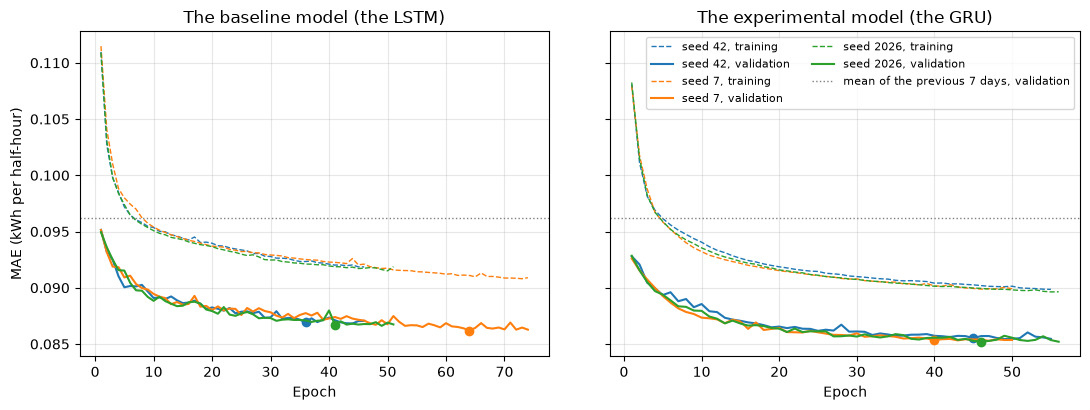

In [49]:
naive_mae = naive_table.loc[
    "mean of the previous 7 days", "MAE (kWh per half-hour)"
]
print(
    "Figure 2: training MAE (the epoch's L1 loss times the scaler's "
    f"standard deviation, {std:.4f} kWh) and validation MAE, by epoch; a dot "
    "marks each run's best epoch, and the dotted line is the validation MAE "
    f"of the mean of the previous 7 days, {naive_mae:.4f} kWh"
)
print(
    "\nThe best epoch of each run, the last that lowered the best validation "
    "MAE so far by more than the minimum improvement, against the lowest "
    "validation MAE in its log, kWh:"
)
for (cell, seed), run in runs.items():
    epoch_maes = [h["validation MAE (kWh)"] for h in run["history"]]
    lowest_epoch = int(np.argmin(epoch_maes))
    print(
        f"  {cell.upper()} seed {seed}: best epoch {run['best_epoch']}, "
        f"{run['best_mae']:.5f}; lowest in the log, epoch {lowest_epoch + 1}, "
        f"{epoch_maes[lowest_epoch]:.5f}; gap "
        f"{run['best_mae'] - epoch_maes[lowest_epoch]:.5f}"
    )
colours = dict(zip(SEEDS, ["tab:blue", "tab:orange", "tab:green"]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, cell, label in zip(
    axes,
    ("lstm", "gru"),
    ("The baseline model (the LSTM)", "The experimental model (the GRU)"),
):
    for seed in SEEDS:
        run = runs[(cell, seed)]
        history = pd.DataFrame(run["history"])
        ax.plot(
            history["epoch"],
            history["training loss"] * std,
            color=colours[seed],
            linestyle="--",
            linewidth=1,
            label=f"seed {seed}, training",
        )
        ax.plot(
            history["epoch"],
            history["validation MAE (kWh)"],
            color=colours[seed],
            linewidth=1.5,
            label=f"seed {seed}, validation",
        )
        ax.plot(run["best_epoch"], run["best_mae"], "o", color=colours[seed])
    ax.axhline(
        naive_mae,
        color="grey",
        linestyle=":",
        linewidth=1,
        label="mean of the previous 7 days, validation",
    )
    ax.set_title(label)
    ax.set_xlabel("Epoch")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("MAE (kWh per half-hour)")
axes[1].legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig("outputs/figure_2_loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 2.** Training MAE (dashed) and validation MAE (solid) by epoch for every run, the baseline model (the LSTM) on the left and the experimental model (the GRU) on the right, on shared axes, with each run's best epoch as a dot. A run's best epoch is the last that lowered the best validation MAE so far by more than 0.0001 kWh, so it is not always the lowest in its log: in five of the six runs a later epoch scored lower by less than that, by at most 0.00009 kWh (the table above). Every run beats the validation MAE of the mean of the previous 7 days, the dotted line, from its first epoch, and the three seeds of each model track one another closely. The GRU learns faster: after the first epoch its validation MAE is about 0.093 kWh against about 0.095 kWh for the LSTM, and at every epoch up to the 46th, where the shortest run stops, each GRU seed's validation MAE is below each LSTM seed's (the epoch logs above). The training MAE stays above the validation MAE in every run. That gap is not by itself a sign of a problem: the training months run through the winter, when use is higher (the scaler's mean over them is 0.2158 kWh per half-hour, against 0.1955 on the validation months), and the training MAE is averaged over each epoch while the weights are still changing. The validation MAE never turns upward for long before a run stops, so the stopping rule ends each run on a plateau.

## Task 5: Evaluate and Compare Model Performance

**Goal.** Score both models and the three naive forecasts on the test months, 1 Nov to 31 Dec 2013, and compare the two models.

**Fixed before the test months are read.** Each of these was written into the notebook before its test cell first ran, so none of them was chosen on the test months:

- **The comparison rule.** A difference in mean MAE smaller than the larger of the two models' standard deviations over their three seeds (the sample standard deviation) is reported as no clear difference. The rule is applied to the validation months first, in the cell below, and the test months are then reported as read.
- **One set of forecasts per model.** Where a view needs one set of forecasts per model, it uses the seed whose validation MAE is the median of that model's three seeds. The cell below fixes the seed from the validation months.
- **Negative forecasts.** A forecast that comes out slightly below zero kWh is scored as it is, because clipping it at zero would change the MAE, and the number of negative forecasts is printed.
- **The views.** The results table gives MAE, MAE divided by mean use, MASE per household (mean and median) and RMSE for the three naive forecasts, and for each model the mean and standard deviation over its seeds. It covers the validation months and the test months, with every household and without the flagged households, and then each tariff group. The error by day type, the forecast examples, the peak-timing confusion matrix, MAE by half-hour and the price-signal days use the median seed. A worst case is the household-day with the largest mean of the two models' MAEs in its day type. The ordinary day is the weekday household-day, from a household without flags, whose mean of the two models' MAEs is closest to the median for such days. The paired comparison by household uses each household's MAE averaged over each model's three seeds.
- **Forecasts made once.** One cell makes every forecast for the test months, both models on every seed and the three naive forecasts, and saves them to `outputs/test_forecasts.npz`. Every table and figure after it reads that file.

In [50]:
def median_seed(maes):
    """Return the seed whose validation MAE is the median of the seeds',
    from a dict of seed to MAE with an odd number of seeds."""
    ranked = sorted(maes, key=maes.get)
    return ranked[len(ranked) // 2]

In [51]:
def comparison_rule(lstm, gru):
    """Apply the written comparison rule to the two models' MAEs, one per
    seed: a difference in mean MAE smaller than the larger of the two
    standard deviations over the seeds is no clear difference. Return the
    difference (the LSTM's mean less the GRU's), that threshold and the
    verdict."""
    difference = float(np.mean(lstm) - np.mean(gru))
    threshold = float(max(np.std(lstm, ddof=1), np.std(gru, ddof=1)))
    if abs(difference) < threshold:
        verdict = "no clear difference"
    elif difference > 0:
        verdict = "the GRU is lower"
    else:
        verdict = "the LSTM is lower"
    return {
        "difference": difference,
        "threshold": threshold,
        "verdict": verdict,
    }

In [52]:
def results_table(actual, naive, models, scale):
    """Return the five scores as text: for each naive forecast, and for
    each model as the mean and standard deviation over its seeds. naive
    maps a name to one forecast and models a name to a list of forecasts,
    one per seed, all shaped like actual; scale holds the MASE scales."""
    rows = {}
    for name, forecast in naive.items():
        scores = forecast_scores(actual, forecast, scale)
        rows[name] = {k: f"{v:.4f}" for k, v in scores.items()}
    for name, forecasts in models.items():
        scores = pd.DataFrame(
            [forecast_scores(actual, f, scale) for f in forecasts]
        )
        rows[name] = {
            k: f"{scores[k].mean():.4f} ± {scores[k].std(ddof=1):.4f}"
            for k in scores
        }
    return pd.DataFrame.from_dict(rows, orient="index")

In [53]:
# Each model's weights are read back from outputs/, so every forecast below
# comes from the files Task 3 and Task 4 saved.
CELLS = {
    "lstm": "the baseline model (the LSTM)",
    "gru": "the experimental model (the GRU)",
}
loaded = {}
for cell in CELLS:
    for seed in SEEDS:
        model = ForecastRNN(
            cell, settings["hidden_size"], settings["num_layers"]
        )
        model.load_state_dict(
            torch.load(f"outputs/{cell}_seed{seed}.pt", weights_only=True)
        )
        loaded[(cell, seed)] = model.to(device)

actual_val = cube[:, validation_days]
val_fc = {
    f"{cell}_seed{seed}": predict(
        model, datasets["validation"], device
    ).reshape(actual_val.shape)
    for (cell, seed), model in loaded.items()
}
np.savez(
    "outputs/validation_forecasts.npz",
    households=households_all.astype(str),
    dates=days[validation_days].astype(str),
    **val_fc,
)

seed_mae = pd.DataFrame(
    {
        cell: {
            seed: np.abs(val_fc[f"{cell}_seed{seed}"] - actual_val).mean()
            for seed in SEEDS
        }
        for cell in CELLS
    }
)
print("Validation MAE by seed, kWh per half-hour (from the saved weights):")
print(seed_mae.map("{:.5f}".format).to_string())
chosen_seed = {cell: median_seed(seed_mae[cell].to_dict()) for cell in CELLS}
print(
    "\nThe median seed on the validation months, used wherever a view needs "
    f"one set of forecasts per model: LSTM seed {chosen_seed['lstm']}, "
    f"GRU seed {chosen_seed['gru']}"
)
rule_val = comparison_rule(seed_mae["lstm"], seed_mae["gru"])
print(
    "\nThe comparison rule on the validation months: mean MAE, LSTM "
    f"{seed_mae['lstm'].mean():.5f} and GRU {seed_mae['gru'].mean():.5f} "
    f"kWh; difference (LSTM less GRU) {rule_val['difference']:+.5f} kWh; "
    "the larger standard deviation over the seeds "
    f"{rule_val['threshold']:.5f} kWh; verdict: {rule_val['verdict']}"
)

subsets = {
    "every household": slice(None),
    f"without the {int(flagged.sum())} flagged households": ~flagged,
}
models_val = {
    label: [val_fc[f"{cell}_seed{seed}"] for seed in SEEDS]
    for cell, label in CELLS.items()
}
for title, rows in subsets.items():
    print(f"\nValidation months, {title}:")
    table = results_table(
        actual_val[rows],
        {name: forecast[rows] for name, forecast in naive.items()},
        {name: [f[rows] for f in fs] for name, fs in models_val.items()},
        scale[rows],
    )
    print(table.to_string())

negatives = {name: int((f < 0).sum()) for name, f in val_fc.items()}
print(
    "\nNegative forecasts on the validation months, scored as they are: "
    + ", ".join(f"{name} {count:,}" for name, count in negatives.items())
    + f", of {actual_val.size:,} forecast half-hours each"
)

Validation MAE by seed, kWh per half-hour (from the saved weights):
         lstm      gru
42    0.08692  0.08552
7     0.08620  0.08536
2026  0.08670  0.08522

The median seed on the validation months, used wherever a view needs one set of forecasts per model: LSTM seed 2026, GRU seed 7

The comparison rule on the validation months: mean MAE, LSTM 0.08661 and GRU 0.08537 kWh; difference (LSTM less GRU) +0.00124 kWh; the larger standard deviation over the seeds 0.00037 kWh; verdict: the GRU is lower

Validation months, every household:
                                 MAE (kWh per half-hour) MAE divided by mean use MASE per household, mean MASE per household, median RMSE (kWh per half-hour)
same half-hour yesterday                          0.1147                  0.5864                   0.9534                     0.9572                   0.2434
same half-hour last week                          0.1165                  0.5961                   0.9688                     0.9572          

                                 MAE (kWh per half-hour) MAE divided by mean use MASE per household, mean MASE per household, median RMSE (kWh per half-hour)
same half-hour yesterday                          0.1116                  0.5870                   0.9602                     0.9598                   0.2312
same half-hour last week                          0.1130                  0.5943                   0.9715                     0.9590                   0.2313
mean of the previous 7 days                       0.0934                  0.4910                   0.8022                     0.7934                   0.1805
the baseline model (the LSTM)            0.0838 ± 0.0004         0.4404 ± 0.0019          0.7210 ± 0.0034            0.7155 ± 0.0032          0.1857 ± 0.0008
the experimental model (the GRU)         0.0826 ± 0.0001         0.4342 ± 0.0007          0.7110 ± 0.0012            0.7038 ± 0.0015          0.1829 ± 0.0007

Negative forecasts on the validation months, scored

In [54]:
# The one cell that forecasts the test months: both models on every seed and
# the three naive forecasts, in one pass, saved for every view below.
test_days = target_days["test"]
actual_shape = (len(cube), len(test_days), day)
test_fc = {
    f"{cell}_seed{seed}": predict(model, datasets["test"], device).reshape(
        actual_shape
    )
    for (cell, seed), model in loaded.items()
}
for name, forecast in naive_forecasts(cube, test_days).items():
    test_fc["naive_" + re.sub(r"\W+", "_", name)] = forecast
np.savez(
    "outputs/test_forecasts.npz",
    households=households_all.astype(str),
    dates=days[test_days].astype(str),
    **test_fc,
)
print(
    f"Forecasts for the test months, {days[test_days[0]]} to "
    f"{days[test_days[-1]]}, saved to outputs/test_forecasts.npz, each "
    "households by days by half-hours:"
)
for name, forecast in test_fc.items():
    digest = hashlib.sha256(forecast.tobytes()).hexdigest()[:16]
    print(f"  {name}: {forecast.shape}, SHA-256 of its values {digest}")
del test_fc

Forecasts for the test months, 2013-11-01 to 2013-12-31, saved to outputs/test_forecasts.npz, each households by days by half-hours:
  lstm_seed42: (1000, 61, 48), SHA-256 of its values a2bf5c0eee2e46b9
  lstm_seed7: (1000, 61, 48), SHA-256 of its values efc628af2815f479
  lstm_seed2026: (1000, 61, 48), SHA-256 of its values 8bc630dab9cc6682
  gru_seed42: (1000, 61, 48), SHA-256 of its values 1602e8c400f9e1a8
  gru_seed7: (1000, 61, 48), SHA-256 of its values a8e7ad431c0dca74
  gru_seed2026: (1000, 61, 48), SHA-256 of its values 5faaba244c31b1bf
  naive_same_half_hour_yesterday: (1000, 61, 48), SHA-256 of its values 769635fadbfb3f1c
  naive_same_half_hour_last_week: (1000, 61, 48), SHA-256 of its values da79d05be9ae7fa2
  naive_mean_of_the_previous_7_days: (1000, 61, 48), SHA-256 of its values 0a32fb85a04f2c97


In [55]:
with np.load("outputs/test_forecasts.npz") as saved:
    test_fc = {name: saved[name] for name in saved.files}
assert list(test_fc.pop("households")) == list(households_all)
test_dates = test_fc.pop("dates")
assert list(test_dates) == list(days[test_days])
actual_test = cube[:, test_days]
naive_test = {
    name: test_fc["naive_" + re.sub(r"\W+", "_", name)] for name in naive
}
models_test = {
    label: [test_fc[f"{cell}_seed{seed}"] for seed in SEEDS]
    for cell, label in CELLS.items()
}
print(
    f"Read {len(test_fc)} forecasts from outputs/test_forecasts.npz: "
    f"{len(households_all):,} households, {len(test_dates)} target days, "
    f"{test_dates[0]} to {test_dates[-1]}"
)
print(
    f"Mean use on the test months: {actual_test.mean():.4f} kWh per "
    f"half-hour, against {actual_val.mean():.4f} on the validation months"
)

Read 9 forecasts from outputs/test_forecasts.npz: 1,000 households, 61 target days, 2013-11-01 to 2013-12-31
Mean use on the test months: 0.2485 kWh per half-hour, against 0.1955 on the validation months


In [56]:
mae = "MAE (kWh per half-hour)"
tables = {}
for title, rows in subsets.items():
    tables[title] = results_table(
        actual_test[rows],
        {name: forecast[rows] for name, forecast in naive_test.items()},
        {name: [f[rows] for f in fs] for name, fs in models_test.items()},
        scale[rows],
    )
    print(f"Test months, {title}:")
    print(tables[title].to_string(), "\n")

val_tables = {
    title: results_table(
        actual_val[rows],
        {name: forecast[rows] for name, forecast in naive.items()},
        {name: [f[rows] for f in fs] for name, fs in models_val.items()},
        scale[rows],
    )
    for title, rows in subsets.items()
}
beside = pd.DataFrame(
    {("validation", title): val_tables[title][mae] for title in subsets}
    | {("test", title): tables[title][mae] for title in subsets}
)
print(f"{mae}, the validation months beside the test months:")
print(beside.to_string())

rule_test = comparison_rule(
    [np.abs(f - actual_test).mean() for f in models_test[CELLS["lstm"]]],
    [np.abs(f - actual_test).mean() for f in models_test[CELLS["gru"]]],
)
print(
    "\nThe comparison rule, as read on the test months: difference (LSTM "
    f"less GRU) {rule_test['difference']:+.5f} kWh, the larger standard "
    f"deviation over the seeds {rule_test['threshold']:.5f} kWh; verdict: "
    f"{rule_test['verdict']}"
)

Test months, every household:
                                 MAE (kWh per half-hour) MAE divided by mean use MASE per household, mean MASE per household, median RMSE (kWh per half-hour)
same half-hour yesterday                          0.1401                  0.5639                   1.1492                     1.1143                   0.2914
same half-hour last week                          0.1426                  0.5739                   1.1709                     1.1216                   0.2939
mean of the previous 7 days                       0.1176                  0.4731                   0.9647                     0.9199                   0.2299
the baseline model (the LSTM)            0.1085 ± 0.0004         0.4365 ± 0.0016          0.8995 ± 0.0078            0.8527 ± 0.0048          0.2366 ± 0.0008
the experimental model (the GRU)         0.1067 ± 0.0002         0.4294 ± 0.0009          0.8909 ± 0.0048            0.8368 ± 0.0006          0.2326 ± 0.0011 



Test months, without the 74 flagged households:
                                 MAE (kWh per half-hour) MAE divided by mean use MASE per household, mean MASE per household, median RMSE (kWh per half-hour)
same half-hour yesterday                          0.1346                  0.5701                   1.1429                     1.1128                   0.2737
same half-hour last week                          0.1364                  0.5779                   1.1596                     1.1166                   0.2751
mean of the previous 7 days                       0.1125                  0.4763                   0.9555                     0.9129                   0.2147
the baseline model (the LSTM)            0.1032 ± 0.0004         0.4369 ± 0.0017          0.8727 ± 0.0040            0.8452 ± 0.0048          0.2203 ± 0.0007
the experimental model (the GRU)         0.1014 ± 0.0002         0.4296 ± 0.0008          0.8576 ± 0.0019            0.8301 ± 0.0016          0.2168 ± 0.0010 



MAE (kWh per half-hour), the validation months beside the test months:
                                       validation                                               test                                  
                                  every household without the 74 flagged households  every household without the 74 flagged households
same half-hour yesterday                   0.1147                            0.1116           0.1401                            0.1346
same half-hour last week                   0.1165                            0.1130           0.1426                            0.1364
mean of the previous 7 days                0.0962                            0.0934           0.1176                            0.1125
the baseline model (the LSTM)     0.0866 ± 0.0004                   0.0838 ± 0.0004  0.1085 ± 0.0004                   0.1032 ± 0.0004
the experimental model (the GRU)  0.0854 ± 0.0002                   0.0826 ± 0.0001  0.1067 ± 0.0002                   

Figure 3: MAE of every forecast; for the two models the bar is the mean over the three seeds and the line one standard deviation


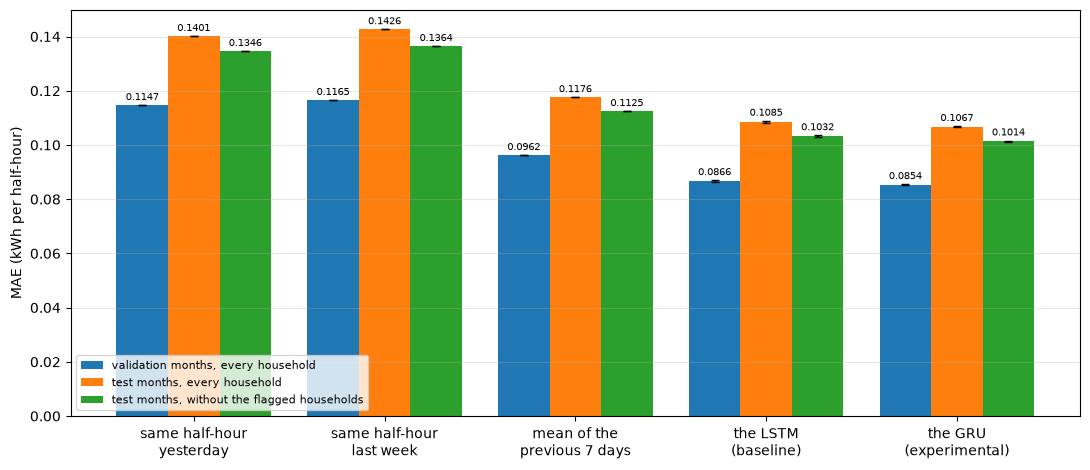

In [57]:
short = {
    "same half-hour yesterday": "same half-hour\nyesterday",
    "same half-hour last week": "same half-hour\nlast week",
    "mean of the previous 7 days": "mean of the\nprevious 7 days",
    CELLS["lstm"]: "the LSTM\n(baseline)",
    CELLS["gru"]: "the GRU\n(experimental)",
}
bars = [
    (
        "validation months, every household",
        actual_val,
        naive,
        models_val,
        slice(None),
    ),
    (
        "test months, every household",
        actual_test,
        naive_test,
        models_test,
        slice(None),
    ),
    (
        "test months, without the flagged households",
        actual_test,
        naive_test,
        models_test,
        ~flagged,
    ),
]
print(
    "Figure 3: MAE of every forecast; for the two models the bar is the "
    "mean over the three seeds and the line one standard deviation"
)
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(short))
for i, (label, actual, nv, md, rows) in enumerate(bars):
    means, spreads = [], []
    for name in short:
        if name in nv:
            means.append(np.abs(nv[name][rows] - actual[rows]).mean())
            spreads.append(0.0)
        else:
            per_seed = [
                np.abs(f[rows] - actual[rows]).mean() for f in md[name]
            ]
            means.append(np.mean(per_seed))
            spreads.append(np.std(per_seed, ddof=1))
    drawn = ax.bar(
        x + (i - 1) * 0.27, means, 0.27, yerr=spreads, capsize=3, label=label
    )
    ax.bar_label(drawn, fmt="%.4f", fontsize=7, padding=2)
ax.set_xticks(x, list(short.values()))
ax.set_ylabel("MAE (kWh per half-hour)")
ax.legend(fontsize=8, loc="lower left")
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("outputs/figure_3_results.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 3.** MAE of every forecast on the validation months and on the test months, with every household and without the flagged households. Both models beat every naive forecast in every setting, and the GRU sits below the LSTM in each. Every forecast errs more on the test months than on the validation months, because use is higher in November and December (0.2485 kWh per half-hour against 0.1955), while MAE divided by mean use in the tables above moves much less. Leaving out the flagged households lowers every forecast's MAE by a similar amount, so the ranking does not rest on them.

In [58]:
everything = {name: [f] for name, f in naive_test.items()} | models_test
tariffs = {"Std": "standard tariff group", "ToU": "time-of-use group"}
metrics = ["MAE divided by mean use", mae, "MASE per household, median"]
by_tariff = {}
for name, forecasts in everything.items():
    row = {}
    for metric in metrics:
        for tariff, label in tariffs.items():
            mine = group == tariff
            row[(metric, label)] = np.mean(
                [
                    forecast_scores(actual_test[mine], f[mine], scale[mine])[
                        metric
                    ]
                    for f in forecasts
                ]
            )
    by_tariff[name] = row
print(
    "Test months by tariff group (for the two models, the mean over their "
    "seeds); mean use "
    + ", ".join(
        f"{label} {actual_test[group == tariff].mean():.4f} kWh per "
        f"half-hour ({int((group == tariff).sum())} households)"
        for tariff, label in tariffs.items()
    )
)
print(pd.DataFrame(by_tariff).T.round(4).to_string())

Test months by tariff group (for the two models, the mean over their seeds); mean use standard tariff group 0.2614 kWh per half-hour (781 households), time-of-use group 0.2028 kWh per half-hour (219 households)
                                 MAE divided by mean use                   MAE (kWh per half-hour)                   MASE per household, median                  
                                   standard tariff group time-of-use group   standard tariff group time-of-use group      standard tariff group time-of-use group
same half-hour yesterday                          0.5550            0.6049                  0.1451            0.1226                     1.1195            1.0976
same half-hour last week                          0.5672            0.6051                  0.1482            0.1227                     1.1303            1.0921
mean of the previous 7 days                       0.4666            0.5034                  0.1220            0.1021                     0.92

In [59]:
model_names = [f"{cell}_seed{seed}" for cell in CELLS for seed in SEEDS]
negatives = {name: int((test_fc[name] < 0).sum()) for name in model_names}
lowest = min(float(test_fc[name].min()) for name in model_names)
print(
    "Negative forecasts on the test months, scored as they are: "
    + ", ".join(f"{name} {count:,}" for name, count in negatives.items())
    + f", of {actual_test.size:,} forecast half-hours each; the lowest is "
    f"{lowest:.4f} kWh"
)

Negative forecasts on the test months, scored as they are: lstm_seed42 4,506, lstm_seed7 13,682, lstm_seed2026 7,690, gru_seed42 7,683, gru_seed7 10,415, gru_seed2026 12,457, of 2,928,000 forecast half-hours each; the lowest is -0.3553 kWh


**What the results show.** On the test months, with every household, the baseline model (the LSTM) scores an MAE of 0.1085 kWh per half-hour and the experimental model (the GRU) 0.1067, against 0.1176 for the mean of the previous 7 days, the best naive forecast. Without the 74 flagged households the three are 0.1032, 0.1014 and 0.1125. Divided by mean use, the two models' MAEs are 0.4365 and 0.4294 against 0.4731, and their median MASE per household, 0.8527 and 0.8368, is below 1, so they beat the error the same half-hour yesterday made on each household's training months.

RMSE tells a different story: the two models score 0.2366 and 0.2326 kWh, both above the 0.2299 of the mean of the previous 7 days. The models were trained on the L1 loss, and a forecast that minimises MAE leads to forecasts of the median, while one that minimises RMSE leads to forecasts of the mean (Hyndman & Athanasopoulos, 2021, sec. 5.8). Household readings are skewed by occasional large uses, so a median forecast sits low and pays most on the large errors that RMSE weighs. The written rule, applied as read on the test months, again finds the GRU lower, by 0.00178 kWh against a larger standard deviation over the seeds of 0.00039 kWh.

By tariff group, both models improve on the naive forecasts in both groups. The time-of-use group's MAE divided by mean use is higher than the standard tariff group's for every forecast, as on the validation months, and that group uses less (0.2028 kWh per half-hour against 0.2614), so the gap is not read as an effect of the price signals. Between 4,506 and 13,682 of each run's 2,928,000 forecast half-hours come out below zero, the lowest at -0.3553 kWh, and they are scored as they are.

**Error by day type, and example forecasts.** Each test household-day falls into the first of these day types that applies: Christmas (24 to 26 Dec); after the clock change (a target day whose input week holds the 27 Oct change, the flag input week crosses a clock change); price-signal day (a time-of-use household on a day the trial gave it a high or low price signal); weekend; and weekday. The table gives each day type's MAE for the two models on their median seeds and for the mean of the previous 7 days. The worst household-day of each day type and one ordinary weekday follow, and Figure 4 draws them.

In [60]:
def day_buckets(dates, crossing, signal):
    """Return a day type for each household-day, shaped like signal
    (households, days), taking the first that applies: "Christmas" (24 to
    26 Dec), "after the clock change" where crossing is True,
    "price-signal day" where signal is True, "weekend", else "weekday"."""
    stamps = pd.to_datetime(pd.Series(dates), format="%Y-%m-%d")
    christmas = (stamps.dt.month == 12) & stamps.dt.day.between(24, 26)
    weekend = stamps.dt.dayofweek >= 5
    plain = np.where(weekend.to_numpy(), "weekend", "weekday")
    out = np.where(np.asarray(signal), "price-signal day", plain[None, :])
    crossing = np.asarray(crossing)[None, :]
    out = np.where(crossing, "after the clock change", out)
    out = np.where(christmas.to_numpy()[None, :], "Christmas", out)
    return out.astype(object)

In [61]:
one_set = {
    "LSTM": test_fc[f"lstm_seed{chosen_seed['lstm']}"],
    "GRU": test_fc[f"gru_seed{chosen_seed['gru']}"],
    "mean of the previous 7 days": naive_test["mean of the previous 7 days"],
}
tou = group == "ToU"
test_label = (
    df[df["tariff_group"] == "ToU"]
    .drop_duplicates("date")
    .set_index("date")["price_signal"]
    .reindex(test_dates)
    .to_numpy()
)
signal = tou[:, None] & (test_label != "none")[None, :]
buckets = day_buckets(test_dates, crossing[test_days], signal)
day_mae = {
    name: np.abs(f - actual_test).mean(axis=2) for name, f in one_set.items()
}
both = (day_mae["LSTM"] + day_mae["GRU"]) / 2
kinds = [
    "Christmas",
    "after the clock change",
    "price-signal day",
    "weekend",
    "weekday",
]
# A day type with no household-days in these months is left out.
kinds = [kind for kind in kinds if (buckets == kind).any()]
rows = {}
for kind in kinds:
    mine = buckets == kind
    row = {
        "household-days": int(mine.sum()),
        "mean use (kWh)": actual_test[mine].mean(),
    }
    for name in one_set:
        row[f"MAE, {name}"] = day_mae[name][mine].mean()
    rows[kind] = row
print(
    "MAE by day type on the test months, kWh per half-hour (median seeds; "
    "each household-day in the first type that applies):"
)
print(pd.DataFrame.from_dict(rows, orient="index").round(4).to_string())

examples = {}
for kind in kinds:
    worst = np.where(buckets == kind, both, -np.inf)
    examples[f"worst, {kind}"] = np.unravel_index(
        np.argmax(worst), worst.shape
    )
ordinary = (buckets == "weekday") & ~flagged[:, None]
middle = np.median(both[ordinary])
nearest = np.where(ordinary, np.abs(both - middle), np.inf)
examples = {
    "ordinary weekday": np.unravel_index(np.argmin(nearest), nearest.shape)
} | examples
print("\nThe household-days Figure 4 draws:")
for name, (h, d) in examples.items():
    reasons = flag_columns["reasons"].iloc[h * len(days) + test_days[d]]
    print(
        f"{name}: {households_all[h]} ({group[h]}), {test_dates[d]} "
        f"({pd.Timestamp(str(test_dates[d])).day_name()}), "
        f"{actual_test[h, d].sum():.2f} kWh in the day; MAE "
        + ", ".join(f"{n} {day_mae[n][h, d]:.4f}" for n in one_set)
        + f" kWh; flags: {reasons or 'none'}"
    )

MAE by day type on the test months, kWh per half-hour (median seeds; each household-day in the first type that applies):
                        household-days  mean use (kWh)  MAE, LSTM  MAE, GRU  MAE, mean of the previous 7 days
Christmas                         3000          0.2706     0.1234    0.1233                            0.1398
after the clock change            3000          0.2192     0.0999    0.0990                            0.1097
price-signal day                  6570          0.2076     0.0941    0.0924                            0.1035
weekend                          14029          0.2655     0.1190    0.1167                            0.1285
weekday                          34401          0.2501     0.1068    0.1047                            0.1146

The household-days Figure 4 draws:
ordinary weekday: MAC001618 (Std), 2013-11-28 (Thursday), 12.27 kWh in the day; MAE LSTM 0.0781, GRU 0.0758, mean of the previous 7 days 0.0852 kWh; flags: none
worst, Christmas: MAC0

Figure 4: the actual readings and the forecasts for the household-days listed above (median seeds)


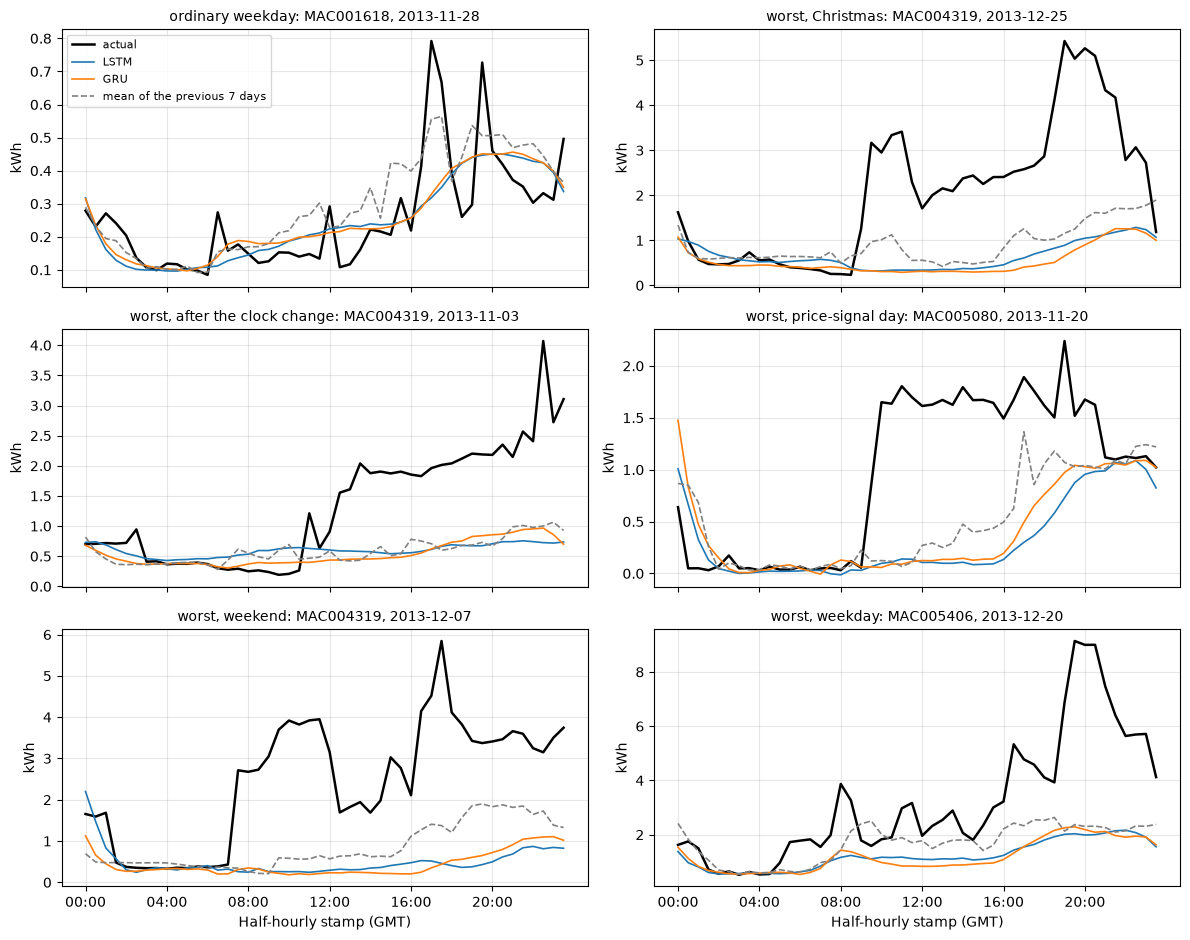

In [62]:
print(
    "Figure 4: the actual readings and the forecasts for the household-days "
    "listed above (median seeds)"
)
fig, axes = plt.subplots(3, 2, figsize=(12, 9.5), sharex=True)
colours = {
    "LSTM": "tab:blue",
    "GRU": "tab:orange",
    "mean of the previous 7 days": "grey",
}
for ax, (name, (h, d)) in zip(axes.ravel(), examples.items()):
    ax.plot(
        stamps, actual_test[h, d], color="black", linewidth=1.8, label="actual"
    )
    for model, forecast in one_set.items():
        ax.plot(
            stamps,
            forecast[h, d],
            color=colours[model],
            linewidth=1.2,
            linestyle="--" if model.startswith("mean") else "-",
            label=model,
        )
    ax.set_title(f"{name}: {households_all[h]}, {test_dates[d]}", fontsize=10)
    ax.set_ylabel("kWh")
    ax.grid(True, alpha=0.3)
unused = len(examples)
for ax in axes.ravel()[unused:]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xticks(range(0, 48, 8), stamps[::8])
    ax.set_xlabel("Half-hourly stamp (GMT)")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(
    "outputs/figure_4_forecast_examples.png", dpi=150, bbox_inches="tight"
)
plt.show()

**Figure 4.** The ordinary weekday, MAC001618 on 2013-11-28, shows the models at their usual: they follow the household's daily shape, low at night and rising into the evening, but smooth it, so the two short evening spikes are missed, as they are by the mean of the previous 7 days. The worst case of every day type comes from a heavy-use household, and three of the five from MAC004319, one of the flagged households. On Christmas Day MAC004319 used 99.79 kWh, most of it from 09:00 on, and both models forecast a much quieter day: MAE 1.5298 kWh for the LSTM and 1.5629 for the GRU, worse than the 1.3277 of the mean of the previous 7 days. In the day-type table Christmas has the highest MAE for every forecast (0.1234 for the LSTM and 0.1233 for the GRU), and the price-signal days the lowest, with the lowest mean use.

**The double penalty.** MAE scores each half-hour on its own, so it can prefer a forecast with the wrong shape to one with the right shape at the wrong time. A forecast that puts a household's peak an hour late is penalised twice, once at the actual peak and once at the forecast one, while a flat forecast is penalised only once (Haben et al., 2021, sec. 3.4). Figure 5 shows this on one household-day from the training months. Both forecasts are built for the illustration, and neither comes from a model: a flat forecast at the day's mean, and the actual day moved one hour late. The household-day is the one in Figure 1's week where the flat forecast's lead is largest.

In [63]:
def flat_and_late(day, previous_day, shift=2):
    """Return the double penalty pair for one day of readings: a flat
    forecast at the day's mean, and the actual day moved shift readings
    late, its first readings taken from the end of the day before."""
    day = np.asarray(day, dtype=float)
    flat = np.full(len(day), day.mean())
    late = np.concatenate([np.asarray(previous_day)[-shift:], day[:-shift]])
    return flat, late

Figure 5: MAC000604 on 2013-03-07, from the training months. A flat forecast at the day's mean, 0.2902 kWh, scores MAE 0.0544 kWh; the actual day moved one hour late scores MAE 0.0719 kWh, though it has the day's exact shape


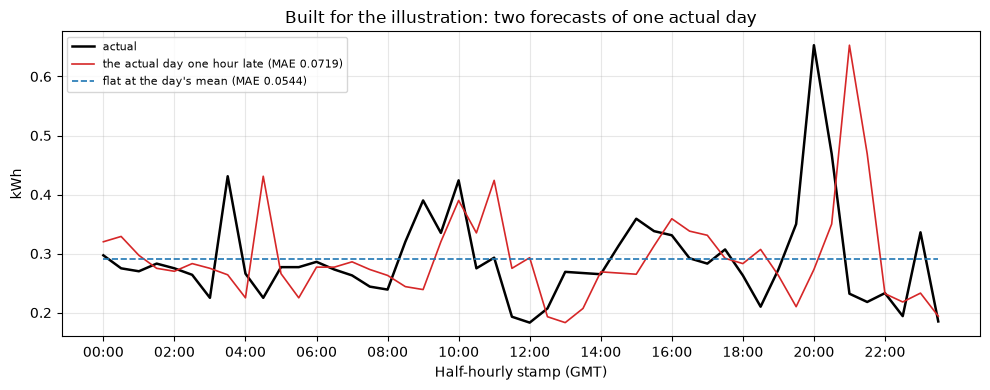

In [64]:
# Built for the illustration, from the training months only: Figure 1's week
# and households, and the household-day where the flat forecast's lead over
# the late one is largest.
week_days = np.flatnonzero((days >= "2013-03-04") & (days <= "2013-03-10"))
pairs = []
for name in households:
    h = int(np.flatnonzero(households_all == name)[0])
    for d in week_days:
        flat, late = flat_and_late(cube[h, d], cube[h, d - 1])
        lead = (
            np.abs(late - cube[h, d]).mean() - np.abs(flat - cube[h, d]).mean()
        )
        pairs.append((lead, h, d))
lead, h, d = max(pairs)
actual_day = cube[h, d]
flat, late = flat_and_late(actual_day, cube[h, d - 1])
flat_mae = np.abs(flat - actual_day).mean()
late_mae = np.abs(late - actual_day).mean()
assert flat_mae < late_mae, "the flat forecast must score the lower MAE"
print(
    f"Figure 5: {households_all[h]} on {days[d]}, from the training months. "
    f"A flat forecast at the day's mean, {actual_day.mean():.4f} kWh, scores "
    f"MAE {flat_mae:.4f} kWh; the actual day moved one hour late scores MAE "
    f"{late_mae:.4f} kWh, though it has the day's exact shape"
)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(stamps, actual_day, color="black", linewidth=1.8, label="actual")
ax.plot(
    stamps,
    late,
    color="tab:red",
    linewidth=1.2,
    label=f"the actual day one hour late (MAE {late_mae:.4f})",
)
ax.plot(
    stamps,
    flat,
    color="tab:blue",
    linestyle="--",
    linewidth=1.2,
    label=f"flat at the day's mean (MAE {flat_mae:.4f})",
)
ax.set_xticks(range(0, 48, 4), stamps[::4])
ax.set_xlabel("Half-hourly stamp (GMT)")
ax.set_ylabel("kWh")
ax.set_title("Built for the illustration: two forecasts of one actual day")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(
    "outputs/figure_5_double_penalty.png", dpi=150, bbox_inches="tight"
)
plt.show()

**Figure 5.** On MAC000604's 2013-03-07, a day in the training months, the flat forecast at the day's mean scores an MAE of 0.0544 kWh and the actual day moved one hour late scores 0.0719 kWh, although the late one holds every rise and peak of the real day. MAE prefers the flat forecast. My reading is that a model trained to lower MAE is pushed the same way: when it cannot tell when a peak will come, a smoothed forecast costs less than a well-shaped one at the wrong time, which fits the smooth forecasts in Figure 4.

**The peak-timing confusion matrix.** A standard confusion matrix counts classes: each case has one true class and one predicted class. A forecast of 48 readings in kWh has no classes, so a standard confusion matrix does not fit it. The peak-timing confusion matrix is how one is made to fit: for each test household-day, the 4-hour block of the day (six a day) holding the actual peak is set against the block holding the forecast's peak. It is a view derived from the forecasts, and MAE stays the headline metric. It shows whether a model catches when a household's use peaks, which MAE cannot show because of the double penalty above.

In [65]:
def peak_blocks(readings, block=8):
    """Return the block of the day holding each day's highest reading, from
    readings shaped (..., readings a day): with 48 readings and blocks of 8,
    six 4-hour blocks from 0 (00:00 to 03:30) to 5 (20:00 to 23:30). A tie
    goes to the earlier reading."""
    return np.argmax(np.asarray(readings), axis=-1) // block

In [66]:
def peak_matrix(actual_blocks, forecast_blocks, blocks=6):
    """Return the peak-timing confusion matrix: household-days counted by the
    block of the actual peak (rows) against the block of the forecast's
    peak (columns), every block on both axes."""
    table = pd.crosstab(
        np.asarray(actual_blocks).ravel(), np.asarray(forecast_blocks).ravel()
    )
    every = range(blocks)
    return table.reindex(index=every, columns=every, fill_value=0)

Figure 6: the peak-timing confusion matrix, a view derived from the forecasts (median seeds), test months; household-days counted by the block of the actual peak against the block of the forecast's peak. 276 household-days hold one value all day, so their actual peak falls in the first block by the tie rule.
Share of household-days on the diagonal (peak in the right block): LSTM 34.5%, GRU 35.6%, mean of the previous 7 days 40.3%


Share of forecast peaks in the two evening blocks, 16:00 to 23:30, by the block of the actual peak:
                 LSTM    GRU
00:00 to 03:30  33.3%  49.8%
04:00 to 07:30  72.1%  72.5%
08:00 to 11:30  83.4%  83.8%
12:00 to 15:30  83.4%  86.3%
16:00 to 19:30  89.6%  91.3%
20:00 to 23:30  85.4%  88.0%


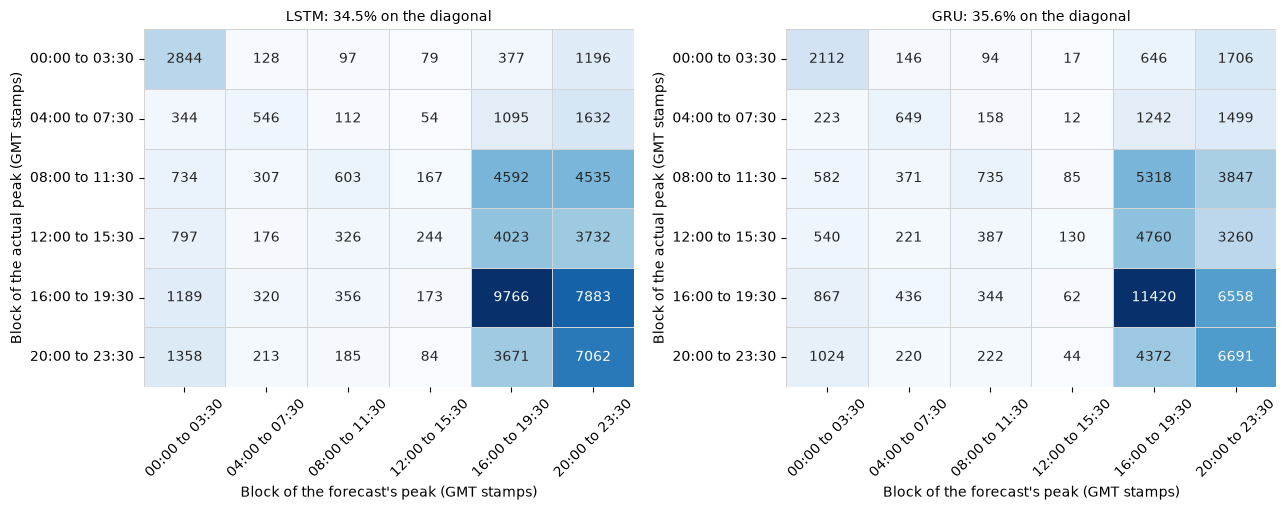

In [67]:
block_names = [f"{4 * b:02d}:00 to {4 * b + 3:02d}:30" for b in range(6)]
actual_blocks = peak_blocks(actual_test)
level = (actual_test == actual_test[..., :1]).all(axis=2)
print(
    "Figure 6: the peak-timing confusion matrix, a view derived from the "
    "forecasts (median seeds), test months; household-days counted by the "
    f"block of the actual peak against the block of the forecast's peak. "
    f"{int(level.sum())} household-days hold one value all day, so their "
    "actual peak falls in the first block by the tie rule."
)
shares = {}
for name, forecast in one_set.items():
    matrix = peak_matrix(actual_blocks, peak_blocks(forecast))
    shares[name] = np.trace(matrix.to_numpy()) / matrix.to_numpy().sum()
print(
    "Share of household-days on the diagonal (peak in the right block): "
    + ", ".join(f"{name} {share:.1%}" for name, share in shares.items())
)
evening_share = pd.DataFrame(
    {
        name: [
            np.isin(
                peak_blocks(one_set[name])[actual_blocks == b], [4, 5]
            ).mean()
            for b in range(6)
        ]
        for name in ("LSTM", "GRU")
    },
    index=block_names,
)
print(
    "Share of forecast peaks in the two evening blocks, 16:00 to 23:30, by "
    "the block of the actual peak:"
)
print(evening_share.map("{:.1%}".format).to_string())
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, name in zip(axes, ("LSTM", "GRU")):
    matrix = peak_matrix(actual_blocks, peak_blocks(one_set[name]))
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cbar=False,
        cmap="Blues",
        mask=matrix == 0,
        linewidths=0.5,
        linecolor="lightgray",
        xticklabels=block_names,
        yticklabels=block_names,
        ax=ax,
    )
    ax.set_title(f"{name}: {shares[name]:.1%} on the diagonal", fontsize=10)
    ax.set_xlabel("Block of the forecast's peak (GMT stamps)")
    ax.set_ylabel("Block of the actual peak (GMT stamps)")
    ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
fig.savefig("outputs/figure_6_peak_timing.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 6.** Most forecast peaks fall in the two evening blocks, 16:00 to 19:30 and 20:00 to 23:30, for every block of the actual peak from 04:00 on (72% to 91% of household-days). The LSTM puts the peak in the right block on 34.5% of the test household-days and the GRU on 35.6%, both below the 40.3% of the mean of the previous 7 days, although both models score a lower MAE. So the models' gain in MAE comes from the level and the general shape of the day, not from timing each day's peak: the double penalty of Figure 5 at work. Where the time of a household's peak matters, MAE alone would overstate both models.

**Extras.** The five views below go beyond what the brief asks. Each is labelled as extra, and none is a second change to either model, which stay as trained (never a second change): E1, a paired comparison by household with a bootstrap interval; E2, MAE by half-hour of the day; E3, the timing table; E4, the price-signal days; and E5, the price signal's own half-hours, a finding made after looking at the data and an association only, whose gap between the groups is weaker in the validation months in the half-hours priced high but larger in those priced low.

In [68]:
def bootstrap_interval(values, resamples=10000, seed=42, level=0.95):
    """Return the percentile bootstrap interval of the mean of values,
    resampling the values with replacement."""
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    picks = rng.integers(0, len(values), size=(resamples, len(values)))
    means = values[picks].mean(axis=1)
    tail = (1 - level) / 2 * 100
    low, high = np.percentile(means, [tail, 100 - tail])
    return float(low), float(high)

In [69]:
by_household = {
    cell: np.mean(
        [
            np.abs(test_fc[f"{cell}_seed{seed}"] - actual_test).mean(
                axis=(1, 2)
            )
            for seed in SEEDS
        ],
        axis=0,
    )
    for cell in CELLS
}
paired = by_household["lstm"] - by_household["gru"]
low, high = bootstrap_interval(paired, resamples=10000, seed=SEED)
print(
    "Extra E1, the paired comparison by household, test months: each "
    "household's MAE averaged over the seeds, LSTM less GRU"
)
print(
    f"Mean difference {paired.mean():+.5f} kWh over {len(paired):,} "
    f"households; 95% bootstrap interval {low:+.5f} to {high:+.5f} kWh "
    f"(10,000 resamples of the households, seed {SEED})"
)
print(
    f"The GRU is lower for {int((paired > 0).sum()):,} households, the LSTM "
    f"for {int((paired < 0).sum()):,}, and {int((paired == 0).sum())} tie"
)

Extra E1, the paired comparison by household, test months: each household's MAE averaged over the seeds, LSTM less GRU
Mean difference +0.00178 kWh over 1,000 households; 95% bootstrap interval +0.00158 to +0.00198 kWh (10,000 resamples of the households, seed 42)
The GRU is lower for 872 households, the LSTM for 128, and 0 tie


**What extra E1 shows.** Paired by household, the LSTM's MAE exceeds the GRU's by 0.00178 kWh on average, and the 95% bootstrap interval over households, 0.00158 to 0.00198 kWh, does not reach zero. The GRU is lower for 872 of the 1,000 households. A comparison of two models needs a statement of its uncertainty, not only a difference (Goodfellow et al., 2016, sec. 5.3.1). Two cautions keep this an extra. Errors within a household are not independent, so the interval is taken over the 1,000 households, far fewer than the large test sets that section has in mind. And the bootstrap is my choice of method, while the written comparison rule decides the headline.

Extra E2, Figure 7: MAE by half-hour of the day, test months (median seeds); the largest for each forecast:
  LSTM: 18:30 0.1710 kWh, 19:00 0.1682 kWh, 18:00 0.1681 kWh
  GRU: 18:30 0.1673 kWh, 19:00 0.1648 kWh, 18:00 0.1642 kWh
  mean of the previous 7 days: 18:30 0.1814 kWh, 19:00 0.1793 kWh, 18:00 0.1785 kWh


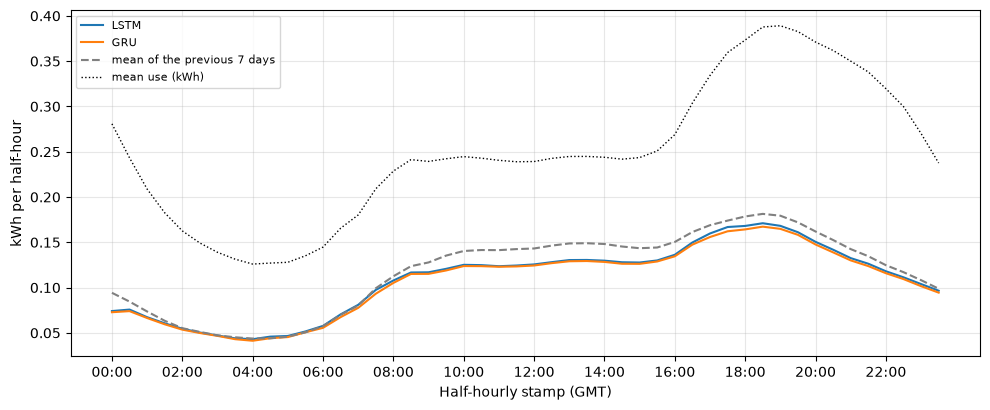

In [70]:
by_half_hour = {
    name: np.abs(f - actual_test).mean(axis=(0, 1))
    for name, f in one_set.items()
}
use_by_half_hour = actual_test.mean(axis=(0, 1))
print(
    "Extra E2, Figure 7: MAE by half-hour of the day, test months (median "
    "seeds); the largest for each forecast:"
)
for name, values in by_half_hour.items():
    top = np.argsort(values)[::-1][:3]
    print(
        f"  {name}: "
        + ", ".join(f"{stamps[i]} {values[i]:.4f} kWh" for i in top)
    )
fig, ax = plt.subplots(figsize=(10, 4.2))
for name, values in by_half_hour.items():
    ax.plot(
        stamps,
        values,
        color=colours[name],
        linewidth=1.5,
        linestyle="--" if name.startswith("mean") else "-",
        label=name,
    )
ax.plot(
    stamps,
    use_by_half_hour,
    color="black",
    linewidth=1,
    linestyle=":",
    label="mean use (kWh)",
)
ax.set_xticks(range(0, 48, 4), stamps[::4])
ax.set_xlabel("Half-hourly stamp (GMT)")
ax.set_ylabel("kWh per half-hour")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(
    "outputs/figure_7_mae_by_half_hour.png", dpi=150, bbox_inches="tight"
)
plt.show()

**Figure 7.** Error follows use through the day: smallest overnight and largest in the early evening, at 18:30 for all three forecasts (0.1710 kWh for the LSTM, 0.1673 for the GRU and 0.1814 for the mean of the previous 7 days). The two models sit close to the naive forecast overnight and below it from the morning on, and the GRU stays a little below the LSTM through the evening peak.

In [71]:
def cpu_step_seconds(
    cell, settings, threads, steps=20, warmup=5, seed=0, length=336
):
    """Return the median seconds a training step (forward, backward,
    clipping and the optimiser's step) and a forecasting step take on the
    CPU, for one batch of random inputs at the settings' batch size: steps
    timed steps of each, after warmup steps that are not counted. PyTorch
    runs on threads CPU threads while it times, whatever the environment
    sets, and gets its own thread count back afterwards."""
    before = torch.get_num_threads()
    torch.set_num_threads(threads)
    try:
        torch.manual_seed(seed)
        model = ForecastRNN(
            cell, settings["hidden_size"], settings["num_layers"]
        )
        optimiser = torch.optim.Adam(
            model.parameters(), lr=settings["learning_rate"]
        )
        x = torch.randn(settings["batch_size"], length, 1)
        y = torch.randn(settings["batch_size"], model.head.out_features)
        loss_fn = nn.L1Loss()
        train_times = []
        for _ in range(warmup + steps):
            started = clock("cpu")
            optimiser.zero_grad()
            loss_fn(model(x), y).backward()
            nn.utils.clip_grad_norm_(model.parameters(), settings["clip_norm"])
            optimiser.step()
            train_times.append(clock("cpu") - started)
        predict_times = []
        with torch.no_grad():
            for _ in range(warmup + steps):
                started = clock("cpu")
                model(x)
                predict_times.append(clock("cpu") - started)
    finally:
        torch.set_num_threads(before)
    return (
        float(np.median(train_times[warmup:])),
        float(np.median(predict_times[warmup:])),
    )

In [72]:
def cpu_estimate(train_step, predict_step, train_batches, val_batches, epochs):
    """Return the estimated seconds of training on the CPU: each epoch is
    train_batches training steps and val_batches forecasting steps, and
    epochs lists the epochs each run took."""
    per_epoch = train_batches * train_step + val_batches * predict_step
    return float(sum(epochs) * per_epoch)

In [73]:
def inference_ms(model, dataset, device, batch_size=256, batches=20, warmup=5):
    """Return the milliseconds a batch of forecasts takes on the device: the
    first warmup batches run untimed, then each of the next batches is timed
    on its own and the median is returned, so one slow batch cannot move it.
    The model's mode is restored afterwards."""
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    inputs = []
    for x, _ in loader:
        inputs.append(x.to(device))
        if len(inputs) == warmup + batches:
            break
    if len(inputs) <= warmup:
        raise ValueError("the dataset holds too few batches to time")
    was_training = model.training
    model.eval()
    times = []
    with torch.no_grad():
        for x in inputs[:warmup]:
            model(x)
        for x in inputs[warmup:]:
            started = clock(device)
            model(x)
            times.append(clock(device) - started)
    model.train(was_training)
    return float(np.median(times)) * 1000

In [74]:
timing = pd.DataFrame(
    [
        {
            "model": cell.upper(),
            "seed": seed,
            "epochs": len(run["history"]),
            "best epoch": run["best_epoch"],
            "seconds an epoch": np.mean(
                [h["seconds"] for h in run["history"]]
            ),
            "seconds in all": run["seconds"],
        }
        for (cell, seed), run in runs.items()
    ]
)
where = torch.cuda.get_device_name(0) if on_gpu else "the CPU"
print(f"Extra E3, the timing table. Training on {where}:")
print(timing.round(1).to_string(index=False))
trained = timing["seconds in all"].sum() + check["seconds"]
print(
    f"Training time, six runs and the pre-flight: {trained:.0f} s, or "
    f"{trained / 60:.1f} minutes"
)

speeds = {
    cell: inference_ms(
        loaded[(cell, chosen_seed[cell])], datasets["validation"], device
    )
    for cell in CELLS
}
print(
    f"\nForecasting time on {where}, the median of 20 batches of "
    f"{settings['batch_size']} windows after 5 warm-up batches (median "
    "seeds): "
    + ", ".join(f"{cell.upper()} {ms:.2f} ms" for cell, ms in speeds.items())
)

# The thread count is fixed in the code, so the estimate does not move with
# what a shell or a clean environment sets. It is 16 at most: timing on all 24
# of this rig's CPUs gave estimates up to 3.5 times higher than on 16.
cpu_threads, timed_steps, warm_ups = min(16, os.cpu_count()), 20, 5
estimate = 0.0
print(
    f"\nThe CPU estimate, with PyTorch fixed at {cpu_threads} CPU threads "
    "(16, or every CPU on a smaller machine, whatever the environment sets): "
    f"the median of {timed_steps} training steps and of {timed_steps} "
    "forecasting steps, each timed on the CPU after "
    f"{warm_ups} warm-up steps, scaled to the epochs each run took"
)
for cell in CELLS:
    train_step, predict_step = cpu_step_seconds(
        cell, settings, cpu_threads, timed_steps, warm_ups
    )
    epochs = list(timing.loc[timing["model"] == cell.upper(), "epochs"])
    if cell == "lstm":
        epochs.append(1)
    seconds = cpu_estimate(
        train_step,
        predict_step,
        batches["training"],
        batches["validation"],
        epochs,
    )
    estimate += seconds
    print(
        f"  {cell.upper()}: {train_step * 1000:.0f} ms a training step, "
        f"{predict_step * 1000:.0f} ms a forecasting step, {sum(epochs)} "
        f"epochs: about {seconds / 3600:.1f} hours"
    )
print(
    f"Estimated training time on the CPU: about {estimate / 3600:.1f} hours, "
    f"against {trained / 60:.1f} minutes on {where}"
)

Extra E3, the timing table. Training on NVIDIA GeForce RTX 5090:
model  seed  epochs  best epoch  seconds an epoch  seconds in all
 LSTM    42      46          36               3.8           176.8
 LSTM     7      74          64               3.8           284.3
 LSTM  2026      51          41               3.8           196.2
  GRU    42      55          45               3.8           209.2
  GRU     7      50          40               3.8           189.3
  GRU  2026      56          46               3.8           212.5
Training time, six runs and the pre-flight: 1273 s, or 21.2 minutes



Forecasting time on NVIDIA GeForce RTX 5090, the median of 20 batches of 256 windows after 5 warm-up batches (median seeds): LSTM 4.54 ms, GRU 0.51 ms

The CPU estimate, with PyTorch fixed at 16 CPU threads (16, or every CPU on a smaller machine, whatever the environment sets): the median of 20 training steps and of 20 forecasting steps, each timed on the CPU after 5 warm-up steps, scaled to the epochs each run took


  LSTM: 544 ms a training step, 25 ms a forecasting step, 172 epochs: about 24.2 hours


  GRU: 503 ms a training step, 72 ms a forecasting step, 161 epochs: about 21.5 hours
Estimated training time on the CPU: about 45.7 hours, against 21.2 minutes on NVIDIA GeForce RTX 5090


**What extra E3 shows.** Training the six runs and the pre-flight took 21.2 minutes on the RTX 5090, at about 4 seconds an epoch for either model; the LSTM's runs stopped after 46 to 74 epochs and the GRU's after 50 to 56. On the GPU both models forecast a batch of 256 within a few milliseconds: in this run 4.54 ms for the LSTM and 0.51 ms for the GRU, the median of 20 timed batches. The times varied too much between runs of the same code to rank the two. On this rig's CPU, with PyTorch fixed at 16 threads, the median training step takes 544 ms for the LSTM and 503 ms for the GRU, so the same training would take about 45.7 hours there. That figure is an estimate scaled from 20 timed steps of each model, not a measured run. The thread count is fixed so that the estimate does not move with the thread count a shell or a clean environment sets. The GRU's fewer weights show in its CPU training step, though its CPU forecasting step was the slower, while its GPU epochs take about as long as the LSTM's.

In [75]:
def signal_day_errors(actual, forecast, tou, label):
    """Return MAE divided by mean use, and bias (mean of actual less
    forecast, over mean use), for the time-of-use group and the standard
    tariff group by the kind of day the time-of-use group was given: "no
    signal", "high", "low", "both" and "any signal". label holds each day's
    kind ("none", "high", "low" or "both"), and tou marks each household of
    the time-of-use group."""
    label = np.asarray(label)
    kinds = {
        "no signal": label == "none",
        "high": label == "high",
        "low": label == "low",
        "both": label == "both",
        "any signal": label != "none",
    }
    groups = {"time-of-use group": tou, "standard tariff group": ~tou}
    rows = {}
    for kind, chosen in kinds.items():
        row = {}
        for group, mine in groups.items():
            a = actual[mine][:, chosen]
            f = forecast[mine][:, chosen]
            row[(group, "MAE divided by mean use")] = (
                np.abs(f - a).mean() / a.mean()
            )
            row[(group, "bias")] = (a - f).mean() / a.mean()
        row[("days", "")] = int(chosen.sum())
        rows[kind] = row
    return pd.DataFrame.from_dict(rows, orient="index")

In [76]:
kinds_given = pd.Series(test_label).value_counts()
print(
    "Extra E4, the price-signal days, test months: the days by the signal "
    "the time-of-use group was given, "
    + ", ".join(f"{kind} {count}" for kind, count in kinds_given.items())
)
for name, forecast in one_set.items():
    table = signal_day_errors(actual_test, forecast, tou, test_label)
    print(f"\n{name}:")
    print(table.round(4).to_string())
    errors = table.xs("MAE divided by mean use", axis=1, level=1)
    ratio = (
        errors.loc["any signal", "time-of-use group"]
        / errors.loc["no signal", "time-of-use group"]
    ) / (
        errors.loc["any signal", "standard tariff group"]
        / errors.loc["no signal", "standard tariff group"]
    )
    print(
        "The time-of-use group's error on signal days against days without, "
        f"over the same ratio for the standard tariff group: {ratio:.3f}"
    )

Extra E4, the price-signal days, test months: the days by the signal the time-of-use group was given, none 29, low 19, both 10, high 3

LSTM:
                 time-of-use group           standard tariff group         days
           MAE divided by mean use    bias MAE divided by mean use    bias     
no signal                   0.4541  0.2115                  0.4399  0.1972   29
high                        0.4388  0.1893                  0.4200  0.1816    3
low                         0.4535  0.2289                  0.4298  0.1896   19
both                        0.4589  0.2206                  0.4289  0.1810   10
any signal                  0.4539  0.2227                  0.4286  0.1861   32
The time-of-use group's error on signal days against days without, over the same ratio for the standard tariff group: 1.026

GRU:
                 time-of-use group           standard tariff group         days
           MAE divided by mean use    bias MAE divided by mean use    bias     
no signa


mean of the previous 7 days:
                 time-of-use group           standard tariff group         days
           MAE divided by mean use    bias MAE divided by mean use    bias     
no signal                   0.5055  0.0072                  0.4720  0.0199   29
high                        0.4991 -0.0248                  0.4616 -0.0132    3
low                         0.4994  0.0213                  0.4607  0.0156   19
both                        0.5061  0.0116                  0.4640  0.0019   10
any signal                  0.5015  0.0141                  0.4618  0.0087   32
The time-of-use group's error on signal days against days without, over the same ratio for the standard tariff group: 1.014


**What extra E4 shows.** The test months held 32 days with a price signal for the time-of-use group (19 low, 10 with both, 3 high) and 29 without. On signal days the time-of-use group's MAE divided by mean use barely moves against its days without a signal (0.4539 against 0.4541 for the LSTM). The standard tariff group's falls on the same dates (0.4286 against 0.4399). So, relative to the standard tariff group, the time-of-use group errs a little more on signal days: a ratio of 1.026 for the LSTM, 1.027 for the GRU and 1.014 for the mean of the previous 7 days. This is an association, not an effect: the trial chose the signal days, the high row rests on 3 days, and the ratio stays close to 1 because a signal covers only some half-hours of a day. The working file holds the price signal by day, not by half-hour, so this view cannot single out the signal's own half-hours. The bias columns also show both models forecasting below the actual readings on every kind of day, by about a fifth of mean use, where the mean of the previous 7 days is close to unbiased: the median that the L1 loss leads to, as the results note explains.

In [77]:
def schedule_grid(schedule, dates):
    """Return the tariff of each half-hour of the given ISO dates, shaped
    (len(dates), 48), from a price schedule with stamp and tariff columns:
    "High", "Low" or "Normal", and "" for a half-hour the schedule has no
    row for. Rows on other dates are ignored. A stamp off the half-hour
    grid, or one given twice, stops it."""
    stamps = pd.to_datetime(schedule["stamp"], format="%Y-%m-%d %H:%M:%S")
    if (stamps != stamps.dt.floor("30min")).any() or stamps.duplicated().any():
        raise ValueError("each stamp must fall on the half-hour grid, once")
    row = pd.Index(dates).get_indexer(stamps.dt.strftime("%Y-%m-%d"))
    column = (stamps.dt.hour * 2 + stamps.dt.minute // 30).to_numpy()
    known = row >= 0
    grid = np.full((len(dates), 48), "", dtype=object)
    grid[row[known], column[known]] = schedule["tariff"].to_numpy()[known]
    return grid

In [78]:
def half_hour_bias(actual, forecast, tou, kinds):
    """Return, for each kind of half-hour, how many half-hours it holds,
    the bias of the time-of-use group and of the standard tariff group
    (mean of actual less forecast, over mean use), and the first less the
    second in percentage points. actual and forecast are shaped
    (households, days, 48), tou marks each household of the time-of-use
    group, and kinds maps a name to a (days, 48) mask."""
    rows = {}
    for kind, mask in kinds.items():
        bias = []
        for mine in (tou, ~tou):
            a = actual[mine][:, mask]
            f = forecast[mine][:, mask]
            bias.append((a - f).mean() / a.mean())
        rows[kind] = {
            "half-hours": int(mask.sum()),
            "bias, time-of-use group": bias[0],
            "bias, standard tariff group": bias[1],
            "difference (points)": 100 * (bias[0] - bias[1]),
        }
    return pd.DataFrame.from_dict(rows, orient="index")

In [79]:
# Only the training and validation months are read here: the price schedule
# loses its rows from 1 Nov as it loads, the readings are cut at 31 Oct, and
# the models' forecasts are the saved validation ones. The cut starts at
# 1 Jan, so every day keeps its index in seen.
schedule = pd.read_csv(
    "lcl_2013_price_schedule.csv", dtype=str, keep_default_na=False
)
schedule = schedule[schedule["stamp"] < "2013-11-01"]
seen_days = np.flatnonzero(day_split != "test")
seen = cube[:, seen_days]
tariff = schedule_grid(schedule, days[seen_days])
bias_days = np.concatenate(
    [target_days["training"], target_days["validation"]]
)
in_validation = day_split[bias_days] == "validation"
naive_seen = naive_forecasts(seen, bias_days)["mean of the previous 7 days"]
actual_seen = seen[:, bias_days]
signal_kinds = {kind: tariff[bias_days] == kind for kind in ("High", "Low")}
left_out = [
    f"{days[bias_days[d]]} {stamps[h]}"
    for d, h in np.argwhere(tariff[bias_days] == "")
]

percent = "{:+.2%}".format
formats = {
    "half-hours": "{:,}".format,
    "bias, time-of-use group": percent,
    "bias, standard tariff group": percent,
    "difference (points)": "{:+.2f}".format,
}
print(
    "Extra E5, the price signal's own half-hours, a finding made after "
    "looking at the data: training and validation months only, "
    f"{days[bias_days[0]]} to {days[bias_days[-1]]}, {len(bias_days)} "
    f"target days, {len(seen):,} households ({int(tou.sum())} in the "
    "time-of-use group)"
)
print(
    "Bias is the mean of actual less forecast, over mean use, for each "
    "group; the difference is the time-of-use group's bias less the "
    "standard tariff group's, in percentage points."
)
print(
    "Half-hours with no row in the price schedule, left out: "
    f"{len(left_out)} ({', '.join(left_out)})"
)
pooled = half_hour_bias(actual_seen, naive_seen, tou, signal_kinds)
print("\nmean of the previous 7 days, training and validation months pooled:")
print(pooled.to_string(formatters=formats))

with np.load("outputs/validation_forecasts.npz") as saved_val:
    assert list(saved_val["households"]) == list(households_all)
    assert list(saved_val["dates"]) == list(days[validation_days])
    val_set = {
        f"{cell.upper()}, seed {chosen_seed[cell]}": saved_val[
            f"{cell}_seed{chosen_seed[cell]}"
        ]
        for cell in CELLS
    }
val_set["mean of the previous 7 days, validation months alone"] = naive_seen[
    :, in_validation
]
print(
    f"\nValidation months alone, {days[validation_days[0]]} to "
    f"{days[validation_days[-1]]}, {len(validation_days)} target days: the "
    "two models on their median seeds, read from "
    "outputs/validation_forecasts.npz, beside the same naive forecast"
)
for name, forecast in val_set.items():
    table = half_hour_bias(
        actual_seen[:, in_validation],
        forecast,
        tou,
        {kind: mask[in_validation] for kind, mask in signal_kinds.items()},
    )
    print(f"\n{name}:")
    print(table.to_string(formatters=formats))

Extra E5, the price signal's own half-hours, a finding made after looking at the data: training and validation months only, 2013-01-08 to 2013-10-31, 297 target days, 1,000 households (219 in the time-of-use group)
Bias is the mean of actual less forecast, over mean use, for each group; the difference is the time-of-use group's bias less the standard tariff group's, in percentage points.
Half-hours with no row in the price schedule, left out: 2 (2013-10-27 01:00, 2013-10-27 01:30)

mean of the previous 7 days, training and validation months pooled:
     half-hours bias, time-of-use group bias, standard tariff group difference (points)
High        624                  -8.44%                      -0.30%               -8.14
Low       1,186                  +7.38%                      -0.52%               +7.90

Validation months alone, 2013-09-01 to 2013-10-31, 61 target days: the two models on their median seeds, read from outputs/validation_forecasts.npz, beside the same naive forecast



LSTM, seed 2026:
     half-hours bias, time-of-use group bias, standard tariff group difference (points)
High        114                 +19.49%                     +22.56%               -3.08
Low         150                 +33.36%                     +24.33%               +9.03

GRU, seed 7:
     half-hours bias, time-of-use group bias, standard tariff group difference (points)
High        114                 +15.76%                     +20.42%               -4.65
Low         150                 +31.44%                     +22.83%               +8.61

mean of the previous 7 days, validation months alone:
     half-hours bias, time-of-use group bias, standard tariff group difference (points)
High        114                  -2.12%                      +4.65%               -6.77
Low         150                 +13.71%                      +4.70%               +9.01


**What extra E5 shows.** This is a finding made after looking at the data: it came from exploring the training and validation months, not from a question set before the data were read, and it is an association only. It reads no test month. The price schedule comes from the data set's own `Tariffs.xlsx`, a separate file the London Datastore page lists among the data set's files as "Tariffs", described as "Time of Use Tariffs for 2013". The page's description of the data set says "The dates/times and the price signal schedule is availaible [sic] as part of this dataset", so it is the same data set, not a join. It lets this view single out the half-hours priced high and the half-hours priced low, which extra E4 could not.

Over the training and validation months together, the mean of the previous 7 days forecast more than the time-of-use group used in the half-hours priced high, a bias of -8.44% of its use there. In the half-hours priced low it forecast less than the group used, a bias of +7.38%. On the same half-hours the standard tariff group's bias was under 1% (-0.30% and -0.52%). So the time-of-use group used less than the mean of its previous 7 days in the half-hours priced high and more in those priced low. That is the direction the trial's own report expected: "a negative kW response" to the high price signal and "a positive kW response (i.e. consumers re-scheduling laundry cycles and energy usage) to the low price" (UK Power Networks, 2015, p. 27). On the same page it reports a load reduction at the high price.

**The caution.** In the validation months alone the gap between the groups is weaker in the half-hours priced high, -6.77 points against -8.14 over both periods, but larger in the half-hours priced low, +9.01 points against +7.90. In the half-hours priced high the time-of-use group's own bias is -2.12%, against +4.65% for the standard tariff group, so most of the gap there comes from the standard tariff group using more than the mean of its previous 7 days. In the half-hours priced low both groups used more (+13.71% and +4.70%), so the standard tariff group no longer sits near zero. These validation figures rest on 114 half-hours priced high and 150 priced low, against 624 and 1,186 over both periods.

**The two models.** On the validation months the LSTM and the GRU, which cannot see the price signal, show a gap between the groups with the same sign as the mean of the previous 7 days. In the half-hours priced high the time-of-use group's bias sits 3.08 points below the standard tariff group's for the LSTM and 4.65 for the GRU, against 6.77; in those priced low it sits 9.03 and 8.61 points above, against 9.01. Both models forecast below the actual readings in these half-hours, with biases from +15.76% to +33.36%, as extra E4 found on the test months, so the gap between the groups is the figure to read here, not the level. The London Datastore page says "The tariff prices were given a day ahead", and a forecast made from past readings alone has no input that carries them.

**Named behaviour examples, drawn from the outputs above.**

**A failure case.** Christmas Day 2013 for MAC004319, one of the flagged households. It used 99.79 kWh that day, most of it from 09:00 on, and both models forecast a much quieter day, with an MAE of 1.5298 kWh for the LSTM and 1.5629 for the GRU, worse than the 1.3277 of the mean of the previous 7 days (Figure 4). It is one instance of a wider pattern: both models forecast low across the test months, by about a fifth of mean use in extra E4's bias columns, and they smooth the peaks, so a heavy-use day is where they fail most.

**A training-behaviour example.** The GRU learns faster than the LSTM on every seed. After its first epoch its validation MAE is about 0.093 kWh against about 0.095 kWh for the LSTM, and at every epoch up to the 46th, where the shortest run stops, each GRU seed's validation MAE is below each LSTM seed's (Figure 2 and the epoch logs). The stopping rule's margin also shows, on LSTM seed 42: epoch 44 reached 0.08683 kWh but beat epoch 36's 0.08692 by less than 0.0001 kWh, so the run kept epoch 36.

**The comparison, under the written rule.** The rule fixed before the test months were read gives this on the validation months: the experimental model (the GRU) has the lower mean MAE, 0.08537 kWh against 0.08661 for the baseline model (the LSTM), a difference of 0.00124 kWh, larger than the larger standard deviation over the seeds, 0.00037 kWh. So the GRU is lower. The same rule, as read on the test months, gives the same verdict, with a difference of 0.00178 kWh against a larger standard deviation of 0.00039 kWh. The GRU gets there with 12,608 fewer parameters (40,944 against 53,552). On the GPU both models forecast a batch of 256 within a few milliseconds (in this run 4.54 ms for the LSTM and 0.51 ms for the GRU), and the times varied too much between runs of the same code to rank the two. On this rig's CPU the GRU's forecasting step was the slower. The difference between the two is small beside the gain of either over the naive forecasts, and both models trail the mean of the previous 7 days on RMSE and on peak timing. So the comparison favours the GRU on MAE, and neither model is the better forecaster of when a household's use peaks.

In [80]:
del loaded, runs, reloaded, model, check, test_fc, val_fc
gc.collect()
if on_gpu:
    torch.cuda.empty_cache()
    print(
        "GPU memory after the release: "
        f"{torch.cuda.memory_allocated() / 2**20:.1f} MiB allocated, "
        f"{torch.cuda.memory_reserved() / 2**20:.1f} MiB reserved by PyTorch"
    )
else:
    print("No GPU memory to release: the notebook ran on the CPU")

GPU memory after the release: 16.0 MiB allocated, 460.0 MiB reserved by PyTorch


**Memory.** The models and forecasts are deleted and PyTorch's cache emptied. What stays allocated, 16.0 MiB, is the cuBLAS workspace that the setup cell's `CUBLAS_WORKSPACE_CONFIG` setting asks for, which PyTorch keeps until the kernel stops, and stopping the kernel returns it to the GPU.

## Summary

[PADDY: a first draft for your own words; your Word text is the master.]

This notebook forecasts one London household's next 24 hours of electricity use, 48 half-hourly readings, from its previous seven days, using the Low Carbon London smart meter data (UK Power Networks) for 1,000 households in 2013. The two models, the baseline model (the LSTM) and the experimental model (the GRU), are two-layer recurrent networks that differ only in the layer type, each trained on three seeds with the L1 loss and the same settings. On the test months, November and December, the GRU's MAE is 0.1067 kWh per half-hour and the LSTM's 0.1085, against 0.1176 for the mean of the previous 7 days, and the written comparison rule finds the GRU lower on the validation and test months. Unexpectedly, both models trail that naive forecast on RMSE and peak timing (35.6% of peaks in the right 4-hour block for the GRU and 34.5% for the LSTM, against 40.3%), which fits forecasts trained to lower MAE that smooth the day and sit low. The hardest days were heavy-use days such as Christmas, and in the half-hours priced high the time-of-use group used less than the mean of its previous 7 days, a finding made after looking at the data, an association only, weaker in the validation months. On the days the time-of-use group was sent a price signal, which neither model can see, its error relative to use held level while the standard tariff group's fell on the same dates, an association only.